[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QFL_GradientHiding_Li2024.ipynb)

# Quantum federated learning with gradient hiding: Li et al. (2024) step by step

**Paper.** Changhao Li, Niraj Kumar, Zhixin Song, Shouvanik Chakrabarti, Marco Pistoia,
*Privacy-preserving quantum federated learning via gradient hiding*,
Quantum Science and Technology 9, 035028 (2024), DOI 10.1088/2058-9565/ad40cc (arXiv:2312.04447).

**What this notebook does.** In federated learning (FL) a server collects the gradients of many clients and updates a
shared model. The paper starts from the known weakness of this scheme: a curious server can run a *gradient inversion
attack* and rebuild the clients' private inputs from the gradients. The authors propose to hide the gradients inside
quantum states that the clients send to the server, so that the server only learns the weighted sum it needs.
The paper is a **protocol-design paper: it has no experiments, no data set and no accuracy table**. Everything it
claims is analytic (a formula for a measurement probability, a communication-cost scaling, a security argument).
So this notebook turns each claim into something you can run:

1. a small, real federated task (handwritten digits, 4 clients, softmax regression, the exact model analysed in the
   paper's Appendix A) with a **plain FedAvg baseline** and a **classical secret-sharing baseline** (paper Sec. III A);
2. the **GHZ phase-aggregation protocol** (Sec. IV A), the **secure multiparty quantum summation protocol**
   (Sec. IV B, phase accumulation + quantum Fourier transform) and the **blind quantum bipartite correlator**
   protocol (Sec. III B, phase-encoded index qubits + quantum counting), all as *gate-level circuits* in PennyLane,
   drawn, and checked against exact closed forms (and, for the GHZ circuit, against an independent Qiskit simulation);
3. federated training with every protocol in the loop, to test the paper's claim that hiding costs **no accuracy**;
4. an **eavesdropper**: the Appendix-A gradient inversion attack run against the plain gradient, the secret-shared
   gradient and the quantum-protocol outputs, and an exact information-theoretic leakage calculation for the BQBC state;
5. communication-cost scaling checks (Table I of the paper), a side-by-side verdict table and a critical reading.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default) takes a few minutes;
`FAST_MODE = False` uses more rounds, seeds and attack trials. No Hugging Face token and no quantum hardware are needed
(the digits data ship with scikit-learn); the notebook never touches real quantum hardware.

**What you get at the end.** Drawn circuits for every protocol, a table of what the server sees under each scheme,
test accuracy of plain / secret-shared / quantum-hidden FL, reconstructed digit images from the attack, scaling plots
of the estimation error versus shots, qubits and counting bits, and a per-claim verdict table.

## The paper in one page

* **Problem.** `m` clients hold private samples; the server minimises `L(theta) = sum_i w_i L_i(theta)` with
  `w_i = N_i / N` by the update `theta <- theta - alpha * sum_i w_i grad L_i(theta)` (Eq. 2). Sending `grad L_i` to the
  server leaks the data (gradient inversion).
* **Decision.** Hide the individual gradients while still letting the server obtain the weighted sum (mod `2 pi`
  for periodic circuit parameters).
* **Classical baseline (Sec. III A, Eqs. 3 to 5).** Pairwise one-time-pad masks `p_ik = s_ik - s_ki mod R` cancel in the
  sum. Cost `O((m + m^2) d)` classical bits. A variant sends the masked values as amplitudes of an `O(log m)` qubit state and
  uses a SWAP test.
* **Protocol I: blind quantum bipartite correlator, BQBC (Sec. III B, III C).** The server prepares index qubits
  `sum_{k,i} |k,i> |a_ki>` (weight bits `a`), every client multiplies in `(-1)^{a_ki b_ki}` (gradient bits `b`) as a phase,
  the server runs *quantum counting* to estimate `(1/(m l0)) sum a_ki b_ki`. Cost `O(m d log(m l0) / eps)`.
  Redundant encoding with parameter `r` (Theorem 1) lowers the chance that the server learns a given bit.
* **Protocol II-a: GHZ aggregation (Sec. IV A).** A `(m+1)`-qubit GHZ state; client `k` writes its gradient into the
  phase of its qubit; the server disentangles and reads `P(0) = (1 + cos sum_k grad L_k) / 2` (Eq. 22). Cost `O(m d / eps^2)`.
  A malicious server can entangle only one client (Eq. 23), so the GHZ state must come from a trusted client.
* **Protocol II-b: secure multiparty quantum summation (Sec. IV B).** Gradients on the grid `{0, delta, ..., 2 pi}` are
  written by QFT into `h = log(2 pi / delta)` qubit registers, accumulated as phases on a shared register through the
  clients (Eqs. 25 to 28); the first client uncomputes an ancilla copy and measures it to detect cheaters (Eq. 29);
  the server's inverse QFT returns `sum_i grad L_i mod 2 pi` (Eq. 30). Cost `(m+1) d h p = O(m d / eps log(m/eps))`.
* **Data.** None. Appendix A analyses a dense layer with softmax and cross-entropy: `dL/dw_ij = (p_j - y_j) x_i`,
  `dL/db_j = p_j - y_j`, hence `x_i = (dL/dw_ij) / (dL/db_j)` for batch size 1 (Eqs. A3 to A5).
* **Claims.** (1) classical secret sharing aggregates exactly; (2) gradient inversion is trivial for batch 1 and not
  uniquely solvable for larger batches; (3) the GHZ readout probability is Eq. 22; (4) the summation protocol returns the
  sum mod `2 pi` and its ancilla test detects a malicious client; (5) BQBC estimates the correlator with `O(1/eps)`
  rounds and the server samples a given index with probability `1/(m l0)`; (6) redundant encoding keeps the
  aggregate recoverable; (7) communication costs of Table I; (8) **no loss of utility**: "the quantum protocols
  presented in this study do not compromise privacy for diminished utility, such as reduced accuracy" (Sec. V).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Experiment, data set, numbers | none (analytic paper, no figures with data) | `# CHOICE:` a real federated task to exercise the protocols: scikit-learn **digits** (1797 images, 8x8, 10 classes), 4 clients, softmax regression (= the dense layer of Appendix A). Not in the paper. |
| Number of clients, weights | `m` clients, `w_i = N_i / N` | `m = 4`, client sizes 320/480/240/240 of a 1280-image training subset, so `w = (0.25, 0.375, 0.1875, 0.1875)` are exact binary fractions (needed for the exact bit expansion in BQBC) |
| Update rule | `theta <- theta - alpha sum w_i grad L_i` | same, one mini-batch gradient per client per round (FedSGD), batch 32, `alpha = 0.5` |
| Gradient range | `[0, 2 pi]` "for simplicity" (Sec. IV B) | `# CHOICE:` phases `phi_k = PHASE_SCALE * w_k * grad_k` with `PHASE_SCALE = 3`, so `|sum phi| < pi`; the server divides by the same public constant |
| GHZ readout (Eq. 22) | Hadamard, then `P(0) = (1 + cos(sum))/2` | `# CHOICE:` **both** quadratures (Hadamard and S-dagger then Hadamard) are measured, because `cos` is even and a single quadrature loses the sign of the aggregate; the phase is `atan2` of the two estimates. Shots are split 50/50. |
| Gradient grid for the summation protocol | `delta`, `h = log(2 pi / delta)` | `h = 10` qubits per register (`delta = 2 pi / 1024`), nearest-grid rounding |
| Classical secret sharing weights | server multiplies masked `y_i` by `w_i` (Eq. 3, 4) | `# CHOICE:` client multiplies by `w_i` **before** masking and arithmetic is fixed-point mod `2^32` (24 fractional bits), so the masks cancel exactly (real-valued mod `R` arithmetic does not commute with the server-side weight) |
| BQBC bit expansion | `w_k . grad_k = l_k a_k b_k`, floating point (Eq. 8, 9) | `# CHOICE:` unsigned fixed point, `l0 = 8` bits; the product of two multi-bit numbers is a convolution of bit strings (Eq. 9), so one counting run is needed for each of the `2 l0 - 1` shifts; gradients are shifted into `[0, 1)` by `(g + 1)/2`, the server removes the known offset |
| Quantum counting | "quantum counting algorithm" | exact QPE of the Grover operator with `t = 14` counting bits, outcome rounded to an integer count, `# CHOICE:` median of 5 independent runs (a single run has a heavy error tail); the training loop samples the exact QPE outcome distribution, which is **asserted equal** to the gate-level circuit |
| Malicious-server privacy of BQBC | probability `1/(m l0)` per round of sampling a given index, redundant encoding | computational-basis measurement is tested directly; in addition an **extension**: exact Holevo information and optimal (Helstrom) single-copy guess of one client bit |
| SWAP-test variant of Sec. III A | amplitude-encoded masked gradients + SWAP test | not implemented (a SWAP test returns the overlap squared and loses the sign); the classical part of the baseline is implemented |
| Eavesdropper | gradient inversion, Appendix A | `# CHOICE:` ratio attack `x = (dL/dw_j) / (dL/db_j)`, label column `j = argmin dL/db`, reconstruction clipped to `[0, 1]`; evaluated at batch size 1 per client |
| Claim thresholds | none (no numbers) | "reproduced" for analytic identities (max error below `1e-9`) and for utility if mean accuracy is within 1 point of plain FedAvg; scaling slopes within 0.15 of the paper's exponent |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Skipped when they are already importable.
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
_need = [m for m in ("pennylane", "qiskit", "sklearn", "scipy") if importlib.util.find_spec(m) is None]
if IN_COLAB or _need:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "pennylane==0.45.1", "qiskit==2.5.2", "pylatexenc"])
    print("Installed. If imports below fail in Colab, use Runtime -> Restart session and Run all again.")
else:
    print("All libraries already available, nothing to install.")

All libraries already available, nothing to install.


In [2]:
# ---------------- Configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False           # True: a few minutes. False: full budgets (see the else branch)

DATA_DIR = "data_cache"     # unused: the digits data ship with scikit-learn (kept for convention)
IBM_TOKEN = ""              # unused: this notebook never touches real quantum hardware

# federated task (CHOICE: the paper has none)
M_CLIENTS = 4               # m
N_TRAIN = 1280              # training subset spread over the clients
CLIENT_SIZES = [320, 480, 240, 240]     # w = N_k / N = (0.25, 0.375, 0.1875, 0.1875), exact binary fractions
BATCH = 32                  # mini-batch per client and round
LR = 0.5                    # alpha in Eq. 2

# protocol knobs
PHASE_SCALE = 3.0           # public constant: phase = PHASE_SCALE * (weighted gradient); |sum| <= 3 < pi
GHZ_SHOTS = 20000           # shots per parameter and round for the GHZ protocol (split over two quadratures)
SMS_H = 10                  # qubits per register of the multiparty summation (grid delta = 2 pi / 2^h)
BQBC_L0 = 8                 # bits per number in the BQBC bit expansion
BQBC_T = 14                 # counting qubits of quantum counting
BQBC_REP = 5                # CHOICE: median over this many independent counting runs (a single QPE run has a heavy error tail)
CSS_FIXED_BITS = 24         # fixed-point fraction bits of the classical secret-sharing baseline
CSS_R_BITS = 32             # modulus R = 2^32
DP_SIGMAS = [0.01, 0.03, 0.1]   # classical Gaussian-noise baseline (std per coordinate of each client's weighted gradient)

if FAST_MODE:
    ROUNDS, N_SEEDS = 60, 3
    ATTACK_TRIALS, SCALING_TRIALS, HOLEVO_DRAWS, SWEEP_ROUNDS = 150, 300, 20, 40
else:
    # Full budget: 150 rounds, 5 seeds, 500 attack trials, 1000 scaling trials, 60 Holevo draws.
    ROUNDS, N_SEEDS = 150, 5
    ATTACK_TRIALS, SCALING_TRIALS, HOLEVO_DRAWS, SWEEP_ROUNDS = 500, 1000, 60, 80
print(dict(FAST_MODE=FAST_MODE, ROUNDS=ROUNDS, N_SEEDS=N_SEEDS, ATTACK_TRIALS=ATTACK_TRIALS, GHZ_SHOTS=GHZ_SHOTS,
           SMS_H=SMS_H, BQBC_L0=BQBC_L0, BQBC_T=BQBC_T))

{'FAST_MODE': False, 'ROUNDS': 150, 'N_SEEDS': 5, 'ATTACK_TRIALS': 500, 'GHZ_SHOTS': 20000, 'SMS_H': 10, 'BQBC_L0': 8, 'BQBC_T': 14}


In [3]:
import os, time, warnings, math, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml
import qiskit, sklearn, scipy
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "figure.max_open_warning": 0})
T_NB0 = time.time()
print("numpy", np.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

numpy 2.5.4 | pennylane 0.45.1 | qiskit 2.5.2 | scikit-learn 1.9.1 | scipy 1.18.1


## Dataset Exploration and Visualisation

The paper contains no data set. To exercise its protocols we need *some* federated learning workload whose gradients can
be attacked, so we use the real **scikit-learn digits** data (1797 handwritten digits, UCI optical recognition data, 8x8
grey-level images, 10 classes) with the model analysed in Appendix A: one dense layer plus softmax plus cross-entropy.
Pixels are divided by 16 (their known maximum), which fits no statistic on any split. The training subset (1280 images,
stratified) is spread over four clients of different size (this is what makes the weights `w_i` non-trivial);
the 360 held-out test images stay with the server. Everything shown below is a real observation coloured by its true digit.

In [4]:
digits = load_digits(as_frame=True)
X_all = digits.data.to_numpy(float) / 16.0            # pixel range is 0..16 by definition of the data set
y_all = digits.target.to_numpy()
print("Full data set shape:", digits.data.shape, "| images are 8x8 =", X_all.shape[1], "pixel features")
print("Feature names (first 5 of 64):", list(digits.data.columns[:5]))
print("Original label values and class counts:")
print(pd.Series(y_all).value_counts().sort_index().to_string())

X_tr_all, X_te, y_tr_all, y_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
X_tr, _, y_tr, _ = train_test_split(X_tr_all, y_tr_all, train_size=N_TRAIN, stratify=y_tr_all, random_state=SEED)
assert sum(CLIENT_SIZES) == N_TRAIN and len(CLIENT_SIZES) == M_CLIENTS
perm = np.random.default_rng(SEED).permutation(N_TRAIN)
bounds = np.cumsum([0] + CLIENT_SIZES)
CLIENT_IDX = [perm[bounds[k]:bounds[k + 1]] for k in range(M_CLIENTS)]
W_CLIENT = np.array(CLIENT_SIZES) / N_TRAIN
CLIENT_OF = np.empty(N_TRAIN, int)
for k, ix in enumerate(CLIENT_IDX):
    CLIENT_OF[ix] = k
Y_tr1h = np.eye(10)[y_tr]
print(f"\ntrain {X_tr.shape} test {X_te.shape} | client sizes {CLIENT_SIZES} | weights w = {W_CLIENT}")
print("train class counts per client (rows = clients, columns = digits 0..9):")
print(pd.crosstab(CLIENT_OF, y_tr).to_string())

Full data set shape: (1797, 64) | images are 8x8 = 64 pixel features
Feature names (first 5 of 64): ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4']
Original label values and class counts:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180



train (1280, 64) test (360, 64) | client sizes [320, 480, 240, 240] | weights w = [0.25   0.375  0.1875 0.1875]


train class counts per client (rows = clients, columns = digits 0..9):


col_0   0   1   2   3   4   5   6   7   8   9
row_0                                        
0      27  35  32  33  28  37  37  37  25  29
1      42  52  46  48  41  54  51  37  53  56
2      32  24  17  28  22  22  17  26  28  24
3      26  19  32  21  38  16  24  27  18  19


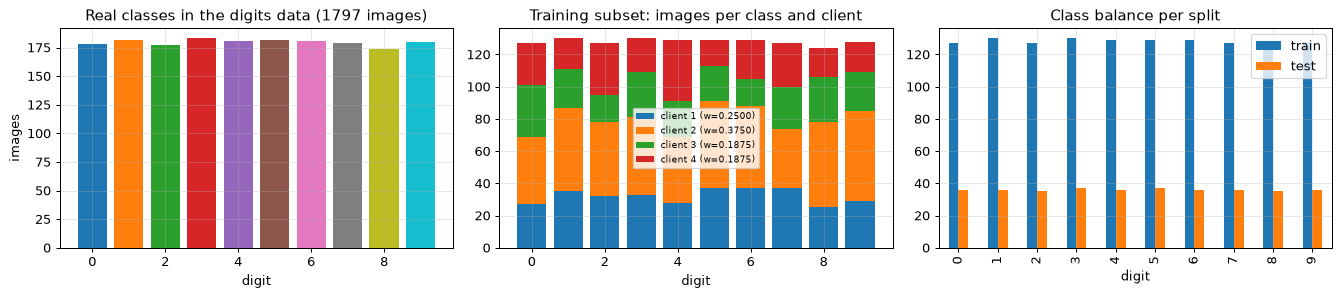

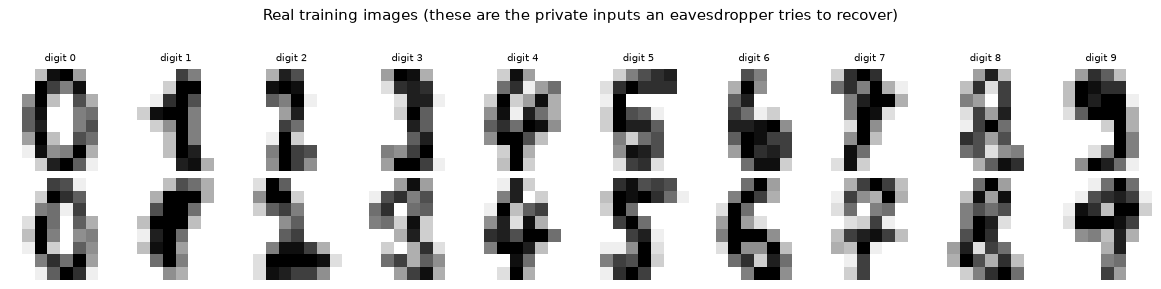

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
cnt = pd.Series(y_all).value_counts().sort_index()
ax[0].bar(cnt.index, cnt.values, color=plt.cm.tab10(np.arange(10)))
ax[0].set_title("Real classes in the digits data (1797 images)"); ax[0].set_xlabel("digit"); ax[0].set_ylabel("images")
ct = pd.crosstab(CLIENT_OF, y_tr)
bottom = np.zeros(10)
for k in range(M_CLIENTS):
    ax[1].bar(ct.columns, ct.loc[k].values, bottom=bottom, label=f"client {k + 1} (w={W_CLIENT[k]:.4f})"); bottom += ct.loc[k].values
ax[1].set_title("Training subset: images per class and client"); ax[1].set_xlabel("digit"); ax[1].legend(fontsize=7)
tt = pd.DataFrame({"train": pd.Series(y_tr).value_counts().sort_index(), "test": pd.Series(y_te).value_counts().sort_index()})
tt.plot.bar(ax=ax[2]); ax[2].set_title("Class balance per split"); ax[2].set_xlabel("digit")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 10, figsize=(13, 3.2))
for c in range(10):
    ix = np.where(y_tr == c)[0][:2]
    for r in range(2):
        ax[r, c].imshow(X_tr[ix[r]].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[r, c].axis("off")
    ax[0, c].set_title(f"digit {c}", fontsize=8)
plt.suptitle("Real training images (these are the private inputs an eavesdropper tries to recover)", y=1.02)
plt.tight_layout(); plt.show()

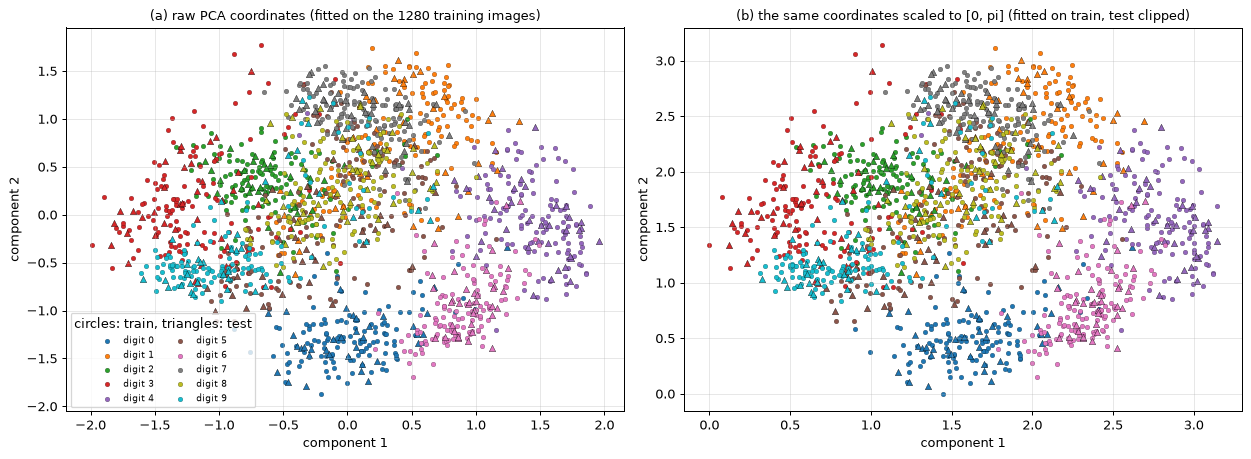

In [6]:
# 2-D views of the real images coloured by ground-truth digit; PCA and scaler fitted on the training split only.
pca2 = PCA(n_components=2, random_state=SEED).fit(X_tr)
P_tr, P_te = pca2.transform(X_tr), pca2.transform(X_te)
ang = MinMaxScaler((0, np.pi)).fit(P_tr)               # [0, pi] coordinates (the phase range used by the protocols)
A_tr, A_te = ang.transform(P_tr), np.clip(ang.transform(P_te), 0, np.pi)
cmap = plt.cm.tab10
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for a_, (T_, Te_, ttl) in zip(ax, [(P_tr, P_te, "(a) raw PCA coordinates (fitted on the 1280 training images)"),
                                   (A_tr, A_te, "(b) the same coordinates scaled to [0, pi] (fitted on train, test clipped)")]):
    for c in range(10):
        s = y_tr == c
        a_.scatter(*T_[s].T, s=14, color=cmap(c), edgecolor="k", linewidth=0.15, label=f"digit {c}")
        t_ = y_te == c
        a_.scatter(*Te_[t_].T, s=26, color=cmap(c), marker="^", edgecolor="k", linewidth=0.3)
    a_.set_title(ttl, fontsize=10); a_.set_xlabel("component 1"); a_.set_ylabel("component 2")
ax[0].legend(fontsize=7, ncol=2, title="circles: train, triangles: test")
plt.tight_layout(); plt.show()

## 1. The federated task, the plain FedAvg baseline and the gradient inversion attack of Appendix A

The model is `o = x W + b`, `p = softmax(o)`, loss = cross-entropy, with `d = 64 * 10 + 10 = 650` parameters. For one image
the gradient is exactly Eqs. A3 and A4 of the paper, `dL/dW_ij = (p_j - y_j) x_i` and `dL/db_j = p_j - y_j`, so the **ratio**
of the two reveals the input pixel `x_i`. Below we (i) check the gradient against finite differences, (ii) verify the ratio
identity to machine precision at batch size 1, (iii) show that it is *not* an identity for larger batches (more unknowns than
equations, as the paper argues), and (iv) define the plain FedAvg baseline.

In [7]:
D_IN, D_OUT = 64, 10
D_PARAM = D_IN * D_OUT + D_OUT                     # d = 650
def unpack(theta):
    return theta[:D_IN * D_OUT].reshape(D_IN, D_OUT), theta[D_IN * D_OUT:]
def softmax(Z):
    Z = Z - Z.max(1, keepdims=True); E = np.exp(Z); return E / E.sum(1, keepdims=True)
def local_grad(theta, X, Y1h):
    # mean cross-entropy gradient of the dense softmax layer (Eqs. A3, A4, A6, A7)
    W, b = unpack(theta); P = softmax(X @ W + b); Dm = (P - Y1h) / len(X)
    return np.concatenate([(X.T @ Dm).ravel(), Dm.sum(0)])
def loss_fn(theta, X, Y1h):
    W, b = unpack(theta); P = softmax(X @ W + b); return float(-(Y1h * np.log(P + 1e-300)).sum(1).mean())
def test_acc(theta):
    W, b = unpack(theta); return float((np.argmax(X_te @ W + b, 1) == y_te).mean())

# (i) finite-difference check of the analytic gradient on a random point
rg = np.random.default_rng(SEED)
th = rg.normal(scale=0.3, size=D_PARAM); xs, ys = X_tr[:5], Y_tr1h[:5]
g = local_grad(th, xs, ys); worst = 0.0
for i in rg.choice(D_PARAM, 12, replace=False):
    e = np.zeros(D_PARAM); e[i] = 1e-6
    worst = max(worst, abs((loss_fn(th + e, xs, ys) - loss_fn(th - e, xs, ys)) / 2e-6 - g[i]))
print(f"max |analytic - finite-difference| over 12 coordinates: {worst:.2e}")

# (ii) Appendix A, Eq. A5: ratio dL/dW_ij / dL/db_j = x_i for batch size 1
def split(vec):
    return vec[:D_IN * D_OUT].reshape(D_IN, D_OUT), vec[D_IN * D_OUT:]
def invert_image(vec):
    # CHOICE: the label column is the one with the most negative bias gradient (p_j - y_j < 0 only for the true class)
    gW, gb = split(vec); j = int(np.argmin(gb))
    if abs(gb[j]) < 1e-12:
        return np.zeros(D_IN), j
    return gW[:, j] / gb[j], j
errs1 = []
for t in range(200):
    i = rg.integers(N_TRAIN); th = rg.normal(scale=0.5, size=D_PARAM)
    xr, j = invert_image(local_grad(th, X_tr[i:i + 1], Y_tr1h[i:i + 1]))
    errs1.append(np.abs(xr - X_tr[i]).max())
print(f"batch size 1: max reconstruction error over 200 random (image, parameter) pairs = {max(errs1):.2e}")

# (iii) larger batches: the mean gradient has n|C|+|C| equations but B(n+|C|) unknowns
INV_B = {}
for B in (2, 8, 32):
    mses = []
    for t in range(200):
        ix = rg.choice(N_TRAIN, B, replace=False); th = rg.normal(scale=0.5, size=D_PARAM)
        xr, j = invert_image(local_grad(th, X_tr[ix], Y_tr1h[ix]))
        xr = np.clip(xr, 0, 1)
        mses.append(min(np.mean((xr - X_tr[i]) ** 2) for i in ix))
    INV_B[B] = float(np.mean(mses))
    print(f"batch size {B:2d}: ratio attack MSE to the closest batch image = {np.mean(mses):.4f} "
          f"(equations {D_PARAM}, unknowns {B * (D_IN + D_OUT)})")
MEAN_IMG = X_tr.mean(0)
print("reference: MSE of the training mean image to a random training image =",
      round(float(np.mean((X_tr - MEAN_IMG) ** 2)), 4))

max |analytic - finite-difference| over 12 coordinates: 3.83e-10
batch size 1: max reconstruction error over 200 random (image, parameter) pairs = 1.11e-16
batch size  2: ratio attack MSE to the closest batch image = 0.0021 (equations 650, unknowns 148)


batch size  8: ratio attack MSE to the closest batch image = 0.0197 (equations 650, unknowns 592)


batch size 32: ratio attack MSE to the closest batch image = 0.0203 (equations 650, unknowns 2368)
reference: MSE of the training mean image to a random training image = 0.0732


## 2. The protocols as code

Each protocol is implemented twice where that is possible: as a **gate-level PennyLane circuit** (small instances, drawn in
the next section) and as a fast **exact vectorised simulator** that is used inside the training loop. The next section
asserts that the two agree. All aggregation functions share one interface: they receive the clients' raw gradients
`G` (shape `m x d`) and weights `w`, and return the server's estimate of `sum_k w_k G_k` together with
**what the server observes** (`per_client` values for schemes that reveal them, a single `aggregate` for the hidden schemes).

### 2.1 Baselines: plain FedAvg, classical secret sharing (paper Sec. III A) and Gaussian-noise DP

In [8]:
M = M_CLIENTS
R_MOD = 1 << CSS_R_BITS
FIX = float(1 << CSS_FIXED_BITS)

def agg_plain(G, w, rng):
    # standard FL: the server receives every client's weighted gradient
    V = w[:, None] * G
    return V.sum(0), dict(kind="per_client", values=V)

def agg_css(G, w, rng):
    # classical secret sharing with one-time pads (Eqs. 3 to 5); CHOICE: weight applied by the client before masking
    U = np.rint(w[:, None] * G * FIX).astype(np.int64) % R_MOD                 # fixed-point, mod R
    S = rng.integers(0, R_MOD, size=(M, M, G.shape[1]), dtype=np.int64)        # S[i,k]: random value client i draws for client k
    P = (S - S.transpose(1, 0, 2)) % R_MOD                                     # p_ik = s_ik - s_ki  (so p_ik = -p_ki, p_ii = 0)
    Y = (U + P.sum(1)) % R_MOD                                                 # masked value each client sends
    tot = Y.sum(0) % R_MOD
    agg = np.where(tot >= R_MOD // 2, tot - R_MOD, tot) / FIX
    seen = np.where(Y >= R_MOD // 2, Y - R_MOD, Y) / FIX                       # what the server sees, as signed numbers
    return agg, dict(kind="per_client", values=seen)

def make_agg_dp(sigma):
    def agg_dp(G, w, rng):
        V = w[:, None] * G + rng.normal(scale=sigma, size=G.shape)             # each client adds Gaussian noise
        return V.sum(0), dict(kind="per_client", values=V)
    return agg_dp

# quick exactness check of the secret-sharing baseline (Eq. 4)
_rg = np.random.default_rng(1); _G = _rg.normal(scale=0.1, size=(M, D_PARAM))
_a, _o = agg_css(_G, W_CLIENT, _rg)
CSS_ERR = float(np.abs(_a - agg_plain(_G, W_CLIENT, _rg)[0]).max())
print("classical secret sharing: max |aggregate - plain weighted sum| =", CSS_ERR,
      "(fixed-point step 2^-24 =", 2.0 ** -24, ")")
print("what the server sees, one client:", np.round(_o["values"][0, :4], 1), "... (uniform in +-", R_MOD / 2 / FIX, ") vs true",
      np.round(W_CLIENT[0] * _G[0, :4], 4))

classical secret sharing: max |aggregate - plain weighted sum| = 9.816123302391899e-08 (fixed-point step 2^-24 = 5.960464477539063e-08 )
what the server sees, one client: [  79.4   31.6  -10.8 -114.8] ... (uniform in +- 128.0 ) vs true [ 0.0086  0.0205  0.0083 -0.0326]


### 2.2 GHZ phase aggregation (paper Sec. IV A, Eqs. 20 to 22)

Wire 0 is the server, wires `1..m` the clients. The server prepares the GHZ state `(|0..0> + |1..1>)/sqrt(2)`, client `k`
applies a phase gate that writes `-phi_k` on its qubit, the server undoes the entanglement with CNOTs, which leaves
`(|0> + e^{-i sum phi}|1>)/sqrt(2)` on its own qubit, and a Hadamard (or S-dagger then Hadamard) turns the phase into a
probability. The same QNode accepts a *batch* of phases (one per model parameter), so one call handles all `d = 650`
parameters of a round.

In [9]:
dev_ghz = qml.device("default.qubit", wires=M + 1)

def _ghz_body(phi, quad, tamper=None):
    # tamper=None: honest GHZ state. tamper=j: malicious server entangles ONLY client j (Eq. 23), the others get |+>.
    qml.Hadamard(wires=0)
    if tamper is None:
        for k in range(1, M + 1):
            qml.CNOT(wires=[0, k])
    else:
        qml.CNOT(wires=[0, tamper])
        for k in range(1, M + 1):
            if k != tamper:
                qml.Hadamard(wires=k)
    for k in range(1, M + 1):                      # client k writes its gradient into the phase of its qubit
        qml.PhaseShift(-phi[..., k - 1], wires=k)
    if tamper is None:                             # server disentangles
        for k in range(1, M + 1):
            qml.CNOT(wires=[0, k])
    else:
        qml.CNOT(wires=[0, tamper])
    if quad == "Y":
        qml.adjoint(qml.S)(wires=0)
    qml.Hadamard(wires=0)

@qml.qnode(dev_ghz)
def ghz_server_probs(phi, quad="X"):
    _ghz_body(phi, quad); return qml.probs(wires=0)

@qml.qnode(dev_ghz)
def ghz_full_probs(phi, quad="X"):
    _ghz_body(phi, quad); return qml.probs(wires=list(range(M + 1)))

@qml.qnode(dev_ghz)
def ghz_malicious_probs(phi, tamper, quad="X"):
    _ghz_body(phi, quad, tamper=tamper); return qml.probs(wires=0)

def agg_ghz(G, w, rng, shots=None):
    shots = GHZ_SHOTS if shots is None else shots
    phi = (PHASE_SCALE * w[:, None] * G).T                    # (d, m), phase written by each client
    n = shots // 2                                            # CHOICE: half of the shots per quadrature
    px = np.clip(np.asarray(ghz_server_probs(phi, "X"))[:, 0], 0, 1)
    py = np.clip(np.asarray(ghz_server_probs(phi, "Y"))[:, 0], 0, 1)
    c = 2 * rng.binomial(n, px) / n - 1                       # estimate of cos(sum phi)
    s = 1 - 2 * rng.binomial(n, py) / n                       # estimate of sin(sum phi)
    est = np.arctan2(s, c) / PHASE_SCALE
    return est, dict(kind="aggregate", values=est)

### 2.3 Secure multiparty quantum summation (paper Sec. IV B, Eqs. 25 to 30)

Client 1 writes its gradient grid index `x_1` into an `h`-qubit register `L`, applies the QFT (so the register holds
`sum_l e^{2 pi i l x_1 / 2^h} |l>`), and copies `L` to an ancilla register `A` with CNOTs. Client `k` holds its index `x_k` in
its own register and applies, controlled on the ancilla value `l`, the phase `e^{2 pi i l x_k / 2^h}` (a product of
controlled-phase gates between the bits of `A` and the bits of the client register). Client 1 uncomputes the copy and
measures `A` (it must read `0`), then sends `L` to the server, whose inverse QFT yields `|sum_k x_k mod 2^h>`.
Because every client register holds a *basis state*, the controlled-phase block is equivalent to single-qubit phase
gates on the ancilla bits; the reduced circuit is also built and asserted equal. The vectorised simulator below is
the closed form of that circuit.

In [10]:
def bits_msb(x, n):
    return [(int(x) >> (n - 1 - i)) & 1 for i in range(n)]

def sms_layout(h, nc):
    L = list(range(h)); A = list(range(h, 2 * h))
    Rg = [list(range(2 * h + (k - 1) * h, 2 * h + k * h)) for k in range(1, nc)]   # registers of clients 2..nc
    return L, A, Rg, 2 * h + (nc - 1) * h

def sms_body(xs, h, full=True, attack_after=None, server_iqft=True):
    # xs: grid indices x_1..x_nc (integers). full=True: explicit client registers + controlled-phase gates.
    # attack_after=k: client k+1 (0-based k) is malicious; returns the mid-circuit measurement values of that client.
    nc = len(xs); N = 2 ** h; L, A, Rg, _ = sms_layout(h, nc); ms = []
    qml.BasisState(np.array(bits_msb(xs[0], h)), wires=L)          # client 1 writes x_1 ...
    qml.QFT(wires=L)                                               # ... and the QFT puts it into the phase
    for j in range(h):
        qml.CNOT(wires=[L[j], A[j]])                               # ancilla copy |l>_a
    for k in range(1, nc):
        if full:
            qml.BasisState(np.array(bits_msb(xs[k], h)), wires=Rg[k - 1])
            for j in range(h):
                for kk in range(h):
                    wj, wk = 2 ** (h - 1 - j), 2 ** (h - 1 - kk)       # bit weights (wire 0 is the most significant bit)
                    qml.ControlledPhaseShift(2 * np.pi * wj * wk / N, wires=[A[j], Rg[k - 1][kk]])
        else:
            for j in range(h):                                     # reduced: register is a basis state, only its value matters
                qml.PhaseShift(2 * np.pi * xs[k] * 2 ** (h - 1 - j) / N, wires=A[j])
        if attack_after == k:                                      # malicious client: inverse QFT on the ancilla, then measure
            qml.adjoint(qml.QFT)(wires=A)
            for j in range(h):
                ms.append(qml.measure(A[j]))
    for j in range(h):
        qml.CNOT(wires=[L[j], A[j]])                               # client 1 uncomputes the copy ...
    # ... and would now measure A (verification: must be |0..0>)
    if server_iqft:
        qml.adjoint(qml.QFT)(wires=L)                              # the server's inverse QFT
    return ms

def make_sms_qnode(h, nc, full=True):
    dev = qml.device("default.qubit", wires=sms_layout(h, nc)[3])
    L, A, _, _ = sms_layout(h, nc)
    @qml.qnode(dev)
    def circuit(xs):
        sms_body(xs, h, full=full)
        return qml.probs(wires=A), qml.probs(wires=L)
    return circuit

def make_sms_state_qnode(h, nc):
    # the state the server holds on L just BEFORE its inverse QFT (reduced circuit)
    dev = qml.device("default.qubit", wires=sms_layout(h, nc)[3]); L = sms_layout(h, nc)[0]
    @qml.qnode(dev)
    def circuit(xs):
        sms_body(xs, h, full=False, server_iqft=False); return qml.density_matrix(wires=L)
    return circuit

def make_sms_attack_qnode(h, nc, attacker):
    # client index `attacker` (1-based position after client 1) applies an inverse QFT to the ancilla register and measures it
    dev = qml.device("default.qubit", wires=sms_layout(h, nc)[3]); L, A, _, _ = sms_layout(h, nc)
    @qml.qnode(dev)
    def circuit(xs):
        ms = sms_body(xs, h, full=False, attack_after=attacker)
        return qml.probs(wires=A), qml.probs(op=ms)
    return circuit

def sms_quantise(phi, h):
    N = 2 ** h; delta = 2 * np.pi / N
    return np.rint(phi / delta).astype(np.int64) % N              # grid index of the phase, mod 2^h

def sms_decode(S, h):
    N = 2 ** h; delta = 2 * np.pi / N
    return np.where(S >= N // 2, S - N, S) * delta               # centre the sum mod 2 pi on (-pi, pi]

def agg_sms(G, w, rng, h=None):
    h = SMS_H if h is None else h
    X = sms_quantise(PHASE_SCALE * w[:, None] * G, h)             # what each client writes into its register
    S = X.sum(0) % (2 ** h)                                       # exact outcome of the circuit (asserted below)
    est = sms_decode(S, h) / PHASE_SCALE
    return est, dict(kind="aggregate", values=est)

### 2.4 Blind quantum bipartite correlator and quantum counting (paper Sec. III B, III C)

For a coordinate, client `k` holds the bits `b_k` of its gradient and everybody knows the bits `a_k` of the weight. The
server prepares `(1/sqrt(N)) sum_{k,i} |k,i>|a_ki>`; client `k` applies `Z` on the `a`-qubit **conditioned on the index
`(k,i)` whenever `b_ki = 1`** (the paper's CZ between the `a`-qubit and a local qubit holding `b_ki`). The state becomes
`sum (-1)^{a_ki b_ki} |k,i>|a_ki>`; the server uncomputes the `a`-qubit, which leaves a phase oracle with `K = sum a_ki b_ki`
marked items out of `N`. Quantum counting (QPE on the Grover operator `G = (2|s><s| - 1) O`, eigenphases `+-2 arcsin sqrt(K/N)`)
returns `K`. Each oracle call is one round trip through all clients, so `2^t - 1` calls are needed for `t` counting bits.

For a multi-bit product `w_k g_k` the bit strings are convolved (Eq. 9): `A_k B_k = sum_lambda 2^lambda C_{k,lambda}` with
`C_{k,lambda} = sum_{i+j=lambda} a_{k,i} b_{k,j}`. Each `lambda` is one correlator, hence `2 l0 - 1` counting runs per parameter.

In [11]:
L0 = BQBC_L0
N_ITEMS = M * L0
N_IDX = int(math.ceil(math.log2(N_ITEMS))); N_PAD = 2 ** N_IDX      # index qubits, padded search space (unused items are unmarked)

_QPE_TAB = {}
def qpe_table(npad, t):
    # exact outcome distribution P(y | K) of quantum counting: QPE on G applied to |s> (equal weight on eigenphases +-u)
    key = (npad, t)
    if key not in _QPE_TAB:
        T = 2 ** t; Kk = np.arange(npad + 1)
        u = np.arcsin(np.sqrt(Kk / npad)) / np.pi
        j = np.arange(T)
        def Q(uu):
            return np.abs(np.fft.fft(np.exp(2j * np.pi * j[None, :] * uu[:, None]), axis=1) / T) ** 2
        _QPE_TAB[key] = 0.5 * (Q(u) + Q(1 - u))
    return _QPE_TAB[key]

def count_estimate(K, npad, t, rng):
    # sample the counting outcome y for each entry of the integer array K and return the real-valued estimate npad*sin^2(pi y/2^t)
    tab = qpe_table(npad, t); cdf = np.cumsum(tab, axis=1); cdf[:, -1] = 1.0
    y = np.empty(K.shape, np.int64)
    for kv in np.unique(K):
        sel = K == kv
        y[sel] = np.minimum(np.searchsorted(cdf[kv], rng.random(sel.sum())), 2 ** t - 1)
    return npad * np.sin(np.pi * y / 2 ** t) ** 2

def bqbc_counts(Gm, w, l0=None):
    # exact marked-item counts K_lambda (lambda = 0..2*l0-2) for every parameter; also returns the integer products A_k * B_k
    l0 = L0 if l0 is None else l0
    A = np.rint(w * 2 ** l0).astype(np.int64)
    assert np.allclose(A, w * 2 ** l0) and (A < 2 ** l0).all(), "weights must be exact l0-bit binary fractions"
    abit = (A[:, None] >> np.arange(l0)) & 1                                      # (m, l0)
    Bq = np.clip(np.rint((Gm + 1) / 2 * 2 ** l0), 0, 2 ** l0 - 1).astype(np.int64)  # CHOICE: shift gradients from [-1, 1] to [0, 1)
    bbit = (Bq[:, :, None] >> np.arange(l0)) & 1                                  # (m, d, l0)
    K = np.zeros((2 * l0 - 1, Gm.shape[1]), np.int64)
    for lam in range(2 * l0 - 1):
        for i in range(max(0, lam - l0 + 1), min(l0 - 1, lam) + 1):
            K[lam] += (abit[:, i][:, None] * bbit[:, :, lam - i]).sum(0)
    return K, A[:, None] * Bq

def agg_bqbc(G, w, rng, t=None, l0=None):
    t = BQBC_T if t is None else t; l0 = L0 if l0 is None else l0
    K, AB = bqbc_counts(G, w, l0)
    assert np.array_equal((K * (2 ** np.arange(2 * l0 - 1))[:, None]).sum(0), AB.sum(0))     # Eq. 9: convolution identity
    # quantum counting returns an integer count; CHOICE: median of BQBC_REP independent runs (confidence boosting),
    # because a single QPE run has a heavy-tailed error (see the failure-rate table in section 6)
    Khat = np.median([np.rint(count_estimate(K, N_PAD, t, rng)) for _ in range(BQBC_REP)], axis=0)
    S = (Khat * (2 ** np.arange(2 * l0 - 1))[:, None]).sum(0) / 2 ** (2 * l0)     # estimate of sum_k w_k g'_k
    est = 2 * S - w.sum()                                                         # remove the public offset: g = 2 g' - 1
    return est, dict(kind="aggregate", values=est)

AGGREGATORS = {"plain FedAvg": agg_plain, "classical secret sharing": agg_css,
               "QFL GHZ": agg_ghz, "QFL multiparty sum": agg_sms, "QFL BQBC": agg_bqbc}
_rg = np.random.default_rng(3); _G = np.clip(_rg.normal(scale=0.05, size=(M, D_PARAM)), -1, 1)
_ref = agg_plain(_G, W_CLIENT, _rg)[0]
for nm, f in AGGREGATORS.items():
    t0_ = time.time(); a_, o_ = f(_G, W_CLIENT, _rg)
    print(f"{nm:26s} server sees {o_['kind']:10s} | max |error| vs plain weighted sum = {np.abs(a_ - _ref).max():.2e} | {time.time() - t0_:.2f}s")

plain FedAvg               server sees per_client | max |error| vs plain weighted sum = 0.00e+00 | 0.00s
classical secret sharing   server sees per_client | max |error| vs plain weighted sum = 9.99e-08 | 0.00s


QFL GHZ                    server sees aggregate  | max |error| vs plain weighted sum = 1.13e-02 | 0.09s
QFL multiparty sum         server sees aggregate  | max |error| vs plain weighted sum = 3.19e-03 | 0.00s


QFL BQBC                   server sees aggregate  | max |error| vs plain weighted sum = 3.03e-03 | 1.23s


## Quantum Circuit Architecture

Every gate-based protocol of the paper is drawn below from the circuit object that is executed, with its qubit count and
depth. None of these circuits has *trained* parameters: the numbers a client writes into a phase gate are its (weighted)
gradient values, i.e. classical data, so "trainable parameters" is replaced by "encoded classical parameters per
client". The instances are small (as the paper's protocols act per model parameter), each followed by assertions that the
circuit equals an exact closed form.

### GHZ aggregation circuit (`m = 4` clients, 5 qubits)

Matplotlib is building the font cache; this may take a moment.


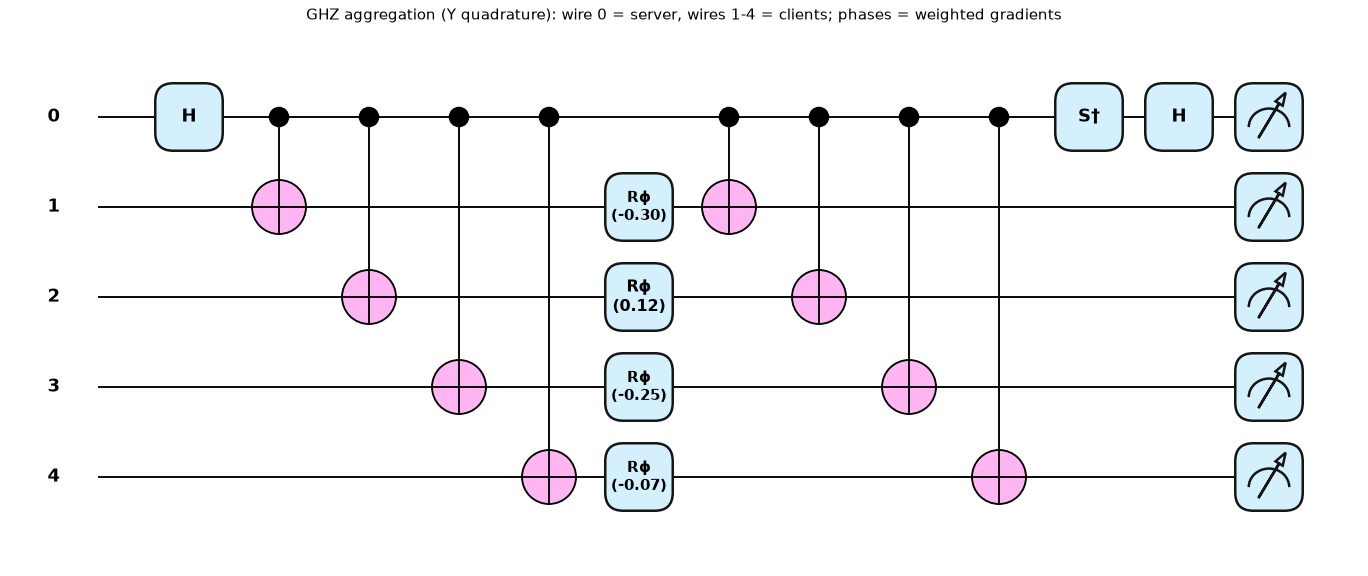

GHZ circuit: {'qubits': 5, 'depth': 10, 'gates': 14, 'depth_native': 10, 'gates_native': 14} | encoded classical parameters: one phase per client = 4 | trainable parameters: 0


In [12]:
def stats(qn, *args, **kw):
    # qubits = device wires; depth/gates of the circuit as written (QFT, QPE, controlled gates counted as one operation each)
    # and of the circuit after decomposition into the device's native gates
    sp = qml.specs(qn)(*args, **kw); r = sp.resources
    out = dict(qubits=sp.num_device_wires, depth=r.depth, gates=r.num_gates)
    try:
        r2 = qml.specs(qn, level="device")(*args, **kw).resources
        out.update(depth_native=r2.depth, gates_native=r2.num_gates)
    except Exception:
        pass
    return out

phi_demo = np.array([0.30, -0.12, 0.25, 0.07])
fig, ax = qml.draw_mpl(ghz_full_probs, decimals=2, style="pennylane")(phi_demo, "Y")
plt.title("GHZ aggregation (Y quadrature): wire 0 = server, wires 1-4 = clients; phases = weighted gradients"); plt.show()
print("GHZ circuit:", stats(ghz_full_probs, phi_demo, "X"), "| encoded classical parameters: one phase per client =", M, "| trainable parameters: 0")

max |circuit - (1+cos sum)/2|  = 5.55e-16   (Eq. 22)
max |circuit - (1-sin sum)/2|  = 5.55e-16   (second quadrature, CHOICE)
max |PennyLane - Qiskit statevector| over 20 circuits = 3.33e-16
probability that all client qubits are back in |0000> after the server's CNOTs (min over 40): 1.000000000000


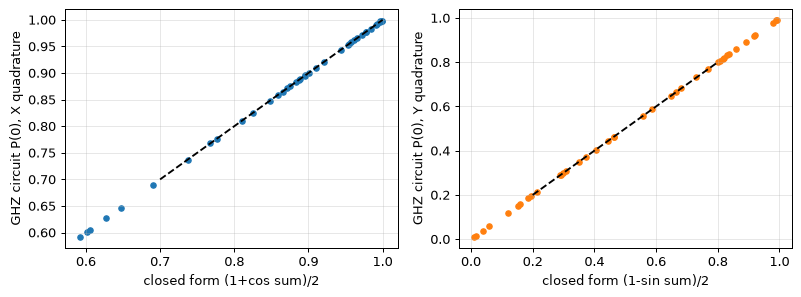

In [13]:
# Exact-simulator equivalence for the GHZ circuit: PennyLane circuit == closed form (Eq. 22) == independent Qiskit simulation
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
rg = np.random.default_rng(SEED)
PHI = rg.uniform(-0.7, 0.7, size=(40, M))
pX = np.asarray(ghz_server_probs(PHI, "X"))[:, 0]; pY = np.asarray(ghz_server_probs(PHI, "Y"))[:, 0]
S_phi = PHI.sum(1)
err_closed_x = np.abs(pX - (1 + np.cos(S_phi)) / 2).max(); err_closed_y = np.abs(pY - (1 - np.sin(S_phi)) / 2).max()
def qiskit_p0(phi, quad):
    qc = QuantumCircuit(M + 1); qc.h(0)
    for k in range(1, M + 1): qc.cx(0, k)
    for k in range(1, M + 1): qc.p(-phi[k - 1], k)
    for k in range(1, M + 1): qc.cx(0, k)
    if quad == "Y": qc.sdg(0)
    qc.h(0)
    return Statevector(qc).probabilities([0])[0]
err_qiskit = max(abs(qiskit_p0(PHI[i], q) - (pX if q == "X" else pY)[i]) for i in range(10) for q in ("X", "Y"))
pf = np.asarray(ghz_full_probs(PHI, "X")); clients_back_in_zero = (pf[:, 0] + pf[:, 2 ** M]).min()
print(f"max |circuit - (1+cos sum)/2|  = {err_closed_x:.2e}   (Eq. 22)")
print(f"max |circuit - (1-sin sum)/2|  = {err_closed_y:.2e}   (second quadrature, CHOICE)")
print(f"max |PennyLane - Qiskit statevector| over 20 circuits = {err_qiskit:.2e}")
print(f"probability that all client qubits are back in |0000> after the server's CNOTs (min over 40): {clients_back_in_zero:.12f}")
assert max(err_closed_x, err_closed_y, err_qiskit) < 1e-9 and clients_back_in_zero > 1 - 1e-9
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].scatter((1 + np.cos(S_phi)) / 2, pX, s=18); ax[0].plot([0.7, 1], [0.7, 1], "k--"); ax[0].set_xlabel("closed form (1+cos sum)/2"); ax[0].set_ylabel("GHZ circuit P(0), X quadrature")
ax[1].scatter((1 - np.sin(S_phi)) / 2, pY, s=18, c="tab:orange"); ax[1].plot([0.2, 0.8], [0.2, 0.8], "k--"); ax[1].set_xlabel("closed form (1-sin sum)/2"); ax[1].set_ylabel("GHZ circuit P(0), Y quadrature")
plt.tight_layout(); plt.show()

### Secure multiparty summation circuit (`h = 3` bits, 3 clients)

The full circuit has the `L` register, the ancilla register `A` and one register for each of clients 2 and 3
(12 qubits). The reduced circuit replaces the client registers by single-qubit phases on `A`.

Matplotlib is building the font cache; this may take a moment.


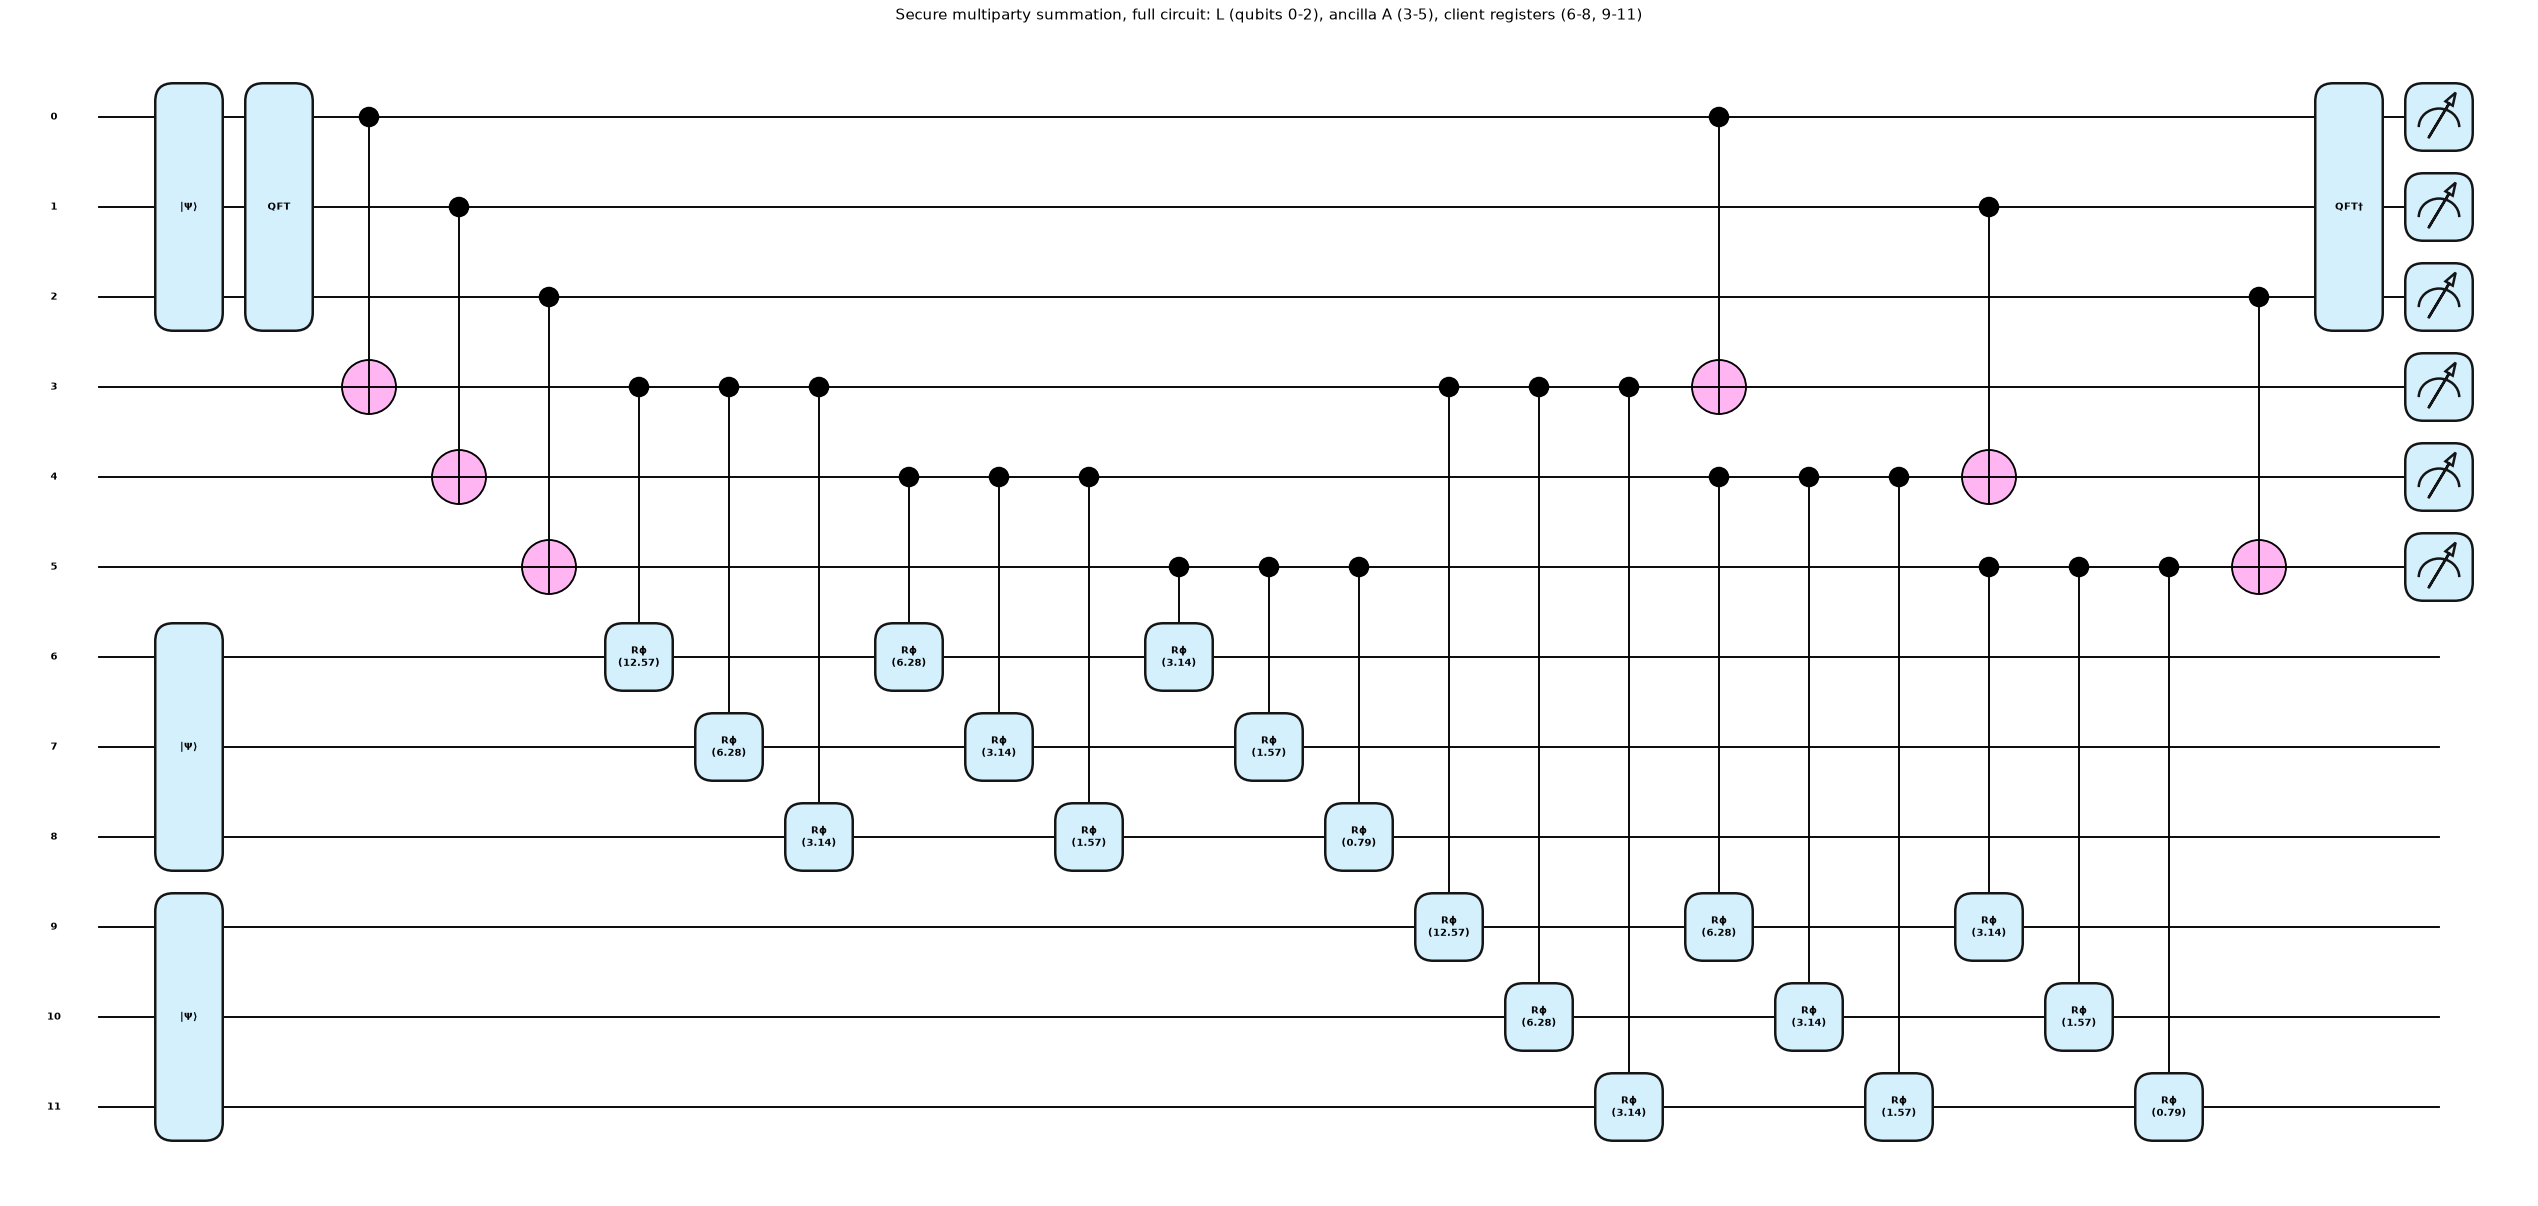

Matplotlib is building the font cache; this may take a moment.


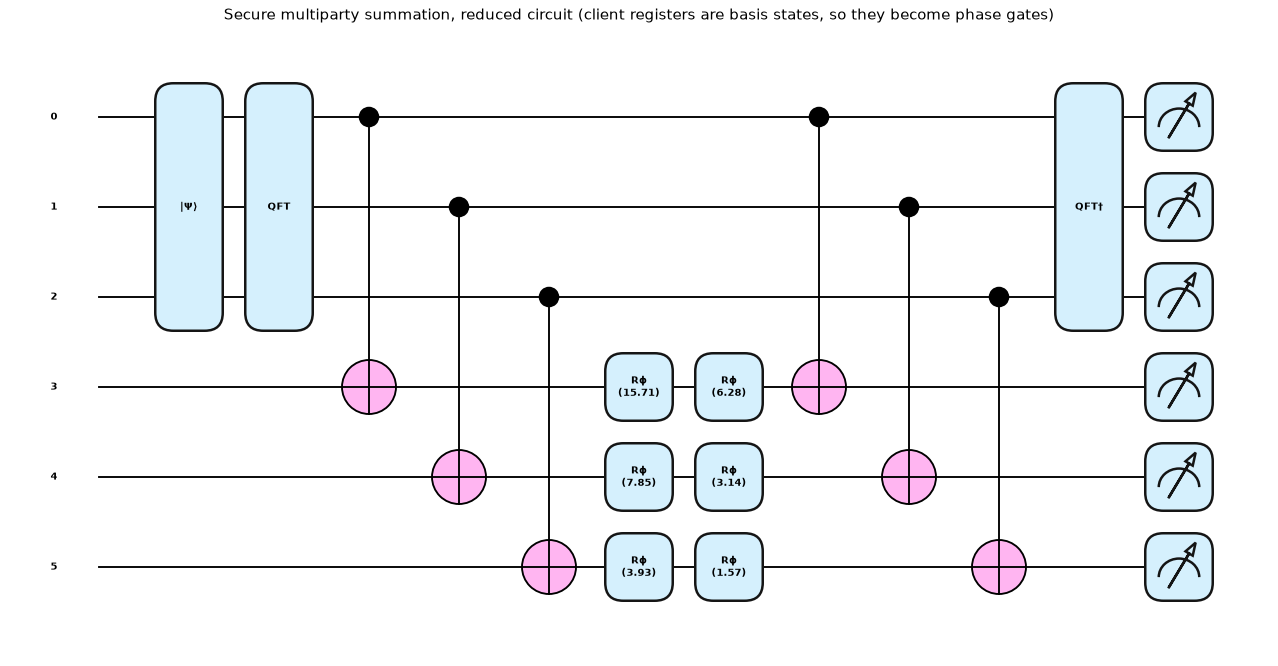

full   circuit: {'qubits': 12, 'depth': 13, 'gates': 29, 'depth_native': 13, 'gates_native': 30} | encoded classical parameters per client: 3 bits | trainable parameters: 0
reduced circuit: {'qubits': 12, 'depth': 7, 'gates': 15, 'depth_native': 7, 'gates_native': 15}


In [14]:
H_DEMO, XS_DEMO = 3, [3, 5, 2]                       # grid indices; the sum is 10 mod 8 = 2
qn_full = make_sms_qnode(H_DEMO, 3, full=True); qn_red = make_sms_qnode(H_DEMO, 3, full=False)
fig, ax = qml.draw_mpl(qn_full, decimals=2, style="pennylane", fontsize=8)(XS_DEMO)
plt.title("Secure multiparty summation, full circuit: L (qubits 0-2), ancilla A (3-5), client registers (6-8, 9-11)"); plt.show()
fig, ax = qml.draw_mpl(qn_red, decimals=2, style="pennylane", fontsize=8)(XS_DEMO)
plt.title("Secure multiparty summation, reduced circuit (client registers are basis states, so they become phase gates)"); plt.show()
print("full   circuit:", stats(qn_full, XS_DEMO), "| encoded classical parameters per client:", H_DEMO, "bits | trainable parameters: 0")
print("reduced circuit:", stats(qn_red, XS_DEMO))

In [15]:
# Equivalence: full circuit == reduced circuit == closed form (server outputs |sum mod 2^h>, ancilla verification outputs |0..0>)
rg = np.random.default_rng(SEED); worst = 0.0; n_check = 0
for h_, nc_ in [(3, 3), (3, 2), (4, 3)]:
    qf, qr = make_sms_qnode(h_, nc_, full=True), make_sms_qnode(h_, nc_, full=False)
    for _ in range(6):
        xs = [int(v) for v in rg.integers(0, 2 ** h_, size=nc_)]
        (pa_f, pl_f), (pa_r, pl_r) = qf(xs), qr(xs)
        target = np.zeros(2 ** h_); target[sum(xs) % 2 ** h_] = 1
        va = np.zeros(2 ** h_); va[0] = 1
        worst = max(worst, np.abs(pl_f - target).max(), np.abs(pl_r - target).max(), np.abs(pl_f - pl_r).max(),
                    np.abs(pa_f - va).max(), np.abs(pa_r - va).max())
        n_check += 1
print(f"{n_check} random instances (h in {{3,4}}, 2-3 clients): max deviation of the circuits from |sum mod 2^h> and of the ancilla from |0..0> = {worst:.2e}")
assert worst < 1e-9
# the vectorised simulator used in training equals the circuit by construction of sms_quantise / modular sum; check the decode too
phi_t = np.array([[0.4, -0.3, 0.1]]).T
Xq = sms_quantise(phi_t, 3)
print("vectorised simulator:", sms_decode(Xq.sum(0) % 8, 3), "vs exact phase sum", phi_t.sum(), "(grid delta = 2pi/8 = %.3f)" % (2 * np.pi / 8))

18 random instances (h in {3,4}, 2-3 clients): max deviation of the circuits from |sum mod 2^h> and of the ancilla from |0..0> = 4.44e-16
vectorised simulator: [0.78539816] vs exact phase sum 0.20000000000000004 (grid delta = 2pi/8 = 0.785)


### BQBC circuits: phase-encoded state and quantum counting (`m = 4` clients, `l0 = 2` bits, 8 items, 3 index qubits)

Matplotlib is building the font cache; this may take a moment.


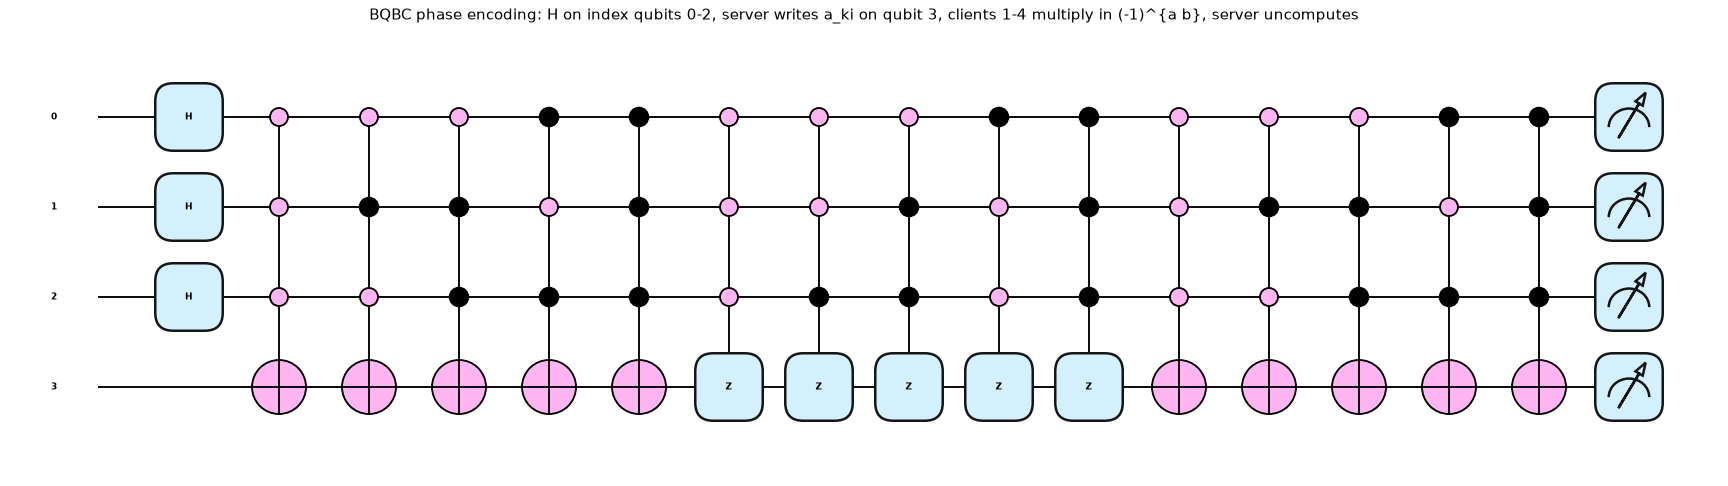

encoding circuit: {'qubits': 4, 'depth': 16, 'gates': 18, 'depth_native': 16, 'gates_native': 18} | encoded classical parameters: 8 gradient bits b_ki (2 per client) | trainable parameters: 0
phase oracle read off the executed circuit: [-1  1  1 -1  1  1  1 -1] | expected (-1)^(a*b): [-1  1  1 -1  1  1  1 -1]


computational-basis distribution of (index, a-qubit) with two different gradient bit strings: max difference 0.0e+00; each index has probability 0.125 = 1/(m l0)


In [16]:
BQ_M, BQ_L0, BQ_N = 4, 2, 8; BQ_NIDX = 3
rg = np.random.default_rng(SEED)
a_demo = np.array([1, 0, 1, 1, 0, 1, 0, 1]); b_demo = np.array([1, 1, 0, 1, 1, 0, 0, 1])      # a: weight bits, b: gradient bits
BQ_IDX, BQ_OA = [0, 1, 2], 3
dev_bq = qml.device("default.qubit", wires=4)

def bq_encode(a_vec, b_vec, uncompute=True):
    for w_ in BQ_IDX:
        qml.Hadamard(wires=w_)                                              # server: uniform superposition of (k,i)
    for j, aj in enumerate(a_vec):
        if aj:
            qml.ctrl(qml.PauliX(wires=BQ_OA), control=BQ_IDX, control_values=bits_msb(j, BQ_NIDX))   # server writes a_ki
    for j, bj in enumerate(b_vec):                                          # client k = j // l0 writes b_ki as a phase
        if bj:
            qml.ctrl(qml.PauliZ(wires=BQ_OA), control=BQ_IDX, control_values=bits_msb(j, BQ_NIDX))
    if uncompute:
        for j, aj in enumerate(a_vec):
            if aj:
                qml.ctrl(qml.PauliX(wires=BQ_OA), control=BQ_IDX, control_values=bits_msb(j, BQ_NIDX))

@qml.qnode(dev_bq)
def bq_state(a_vec, b_vec):
    bq_encode(a_vec, b_vec); return qml.state()

@qml.qnode(dev_bq)
def bq_probs_comp(a_vec, b_vec):
    bq_encode(a_vec, b_vec, uncompute=False); return qml.probs(wires=BQ_IDX + [BQ_OA])

fig, ax = qml.draw_mpl(bq_state, decimals=0, style="pennylane", fontsize=7)(a_demo, b_demo)
plt.title("BQBC phase encoding: H on index qubits 0-2, server writes a_ki on qubit 3, clients 1-4 multiply in (-1)^{a b}, server uncomputes"); plt.show()
print("encoding circuit:", stats(bq_state, a_demo, b_demo), "| encoded classical parameters: 8 gradient bits b_ki (2 per client) | trainable parameters: 0")
psi = np.asarray(bq_state(a_demo, b_demo)).reshape(8, 2)[:, 0] * np.sqrt(8)       # amplitudes with the a-qubit back in |0>
sign_from_circuit = np.real(psi)
print("phase oracle read off the executed circuit:", np.round(sign_from_circuit).astype(int), "| expected (-1)^(a*b):", (1 - 2 * a_demo * b_demo))
assert np.allclose(sign_from_circuit, 1 - 2 * a_demo * b_demo, atol=1e-9) and np.allclose(np.asarray(bq_state(a_demo, b_demo)).reshape(8, 2)[:, 1], 0, atol=1e-12)
# privacy at the level of the computational basis: the server's Z-basis statistics do not depend on the clients' bits
pc1 = np.asarray(bq_probs_comp(a_demo, b_demo)); pc2 = np.asarray(bq_probs_comp(a_demo, 1 - b_demo))
print(f"computational-basis distribution of (index, a-qubit) with two different gradient bit strings: max difference {np.abs(pc1 - pc2).max():.1e}; each index has probability {1 / BQ_N:.3f} = 1/(m l0)")

Matplotlib is building the font cache; this may take a moment.


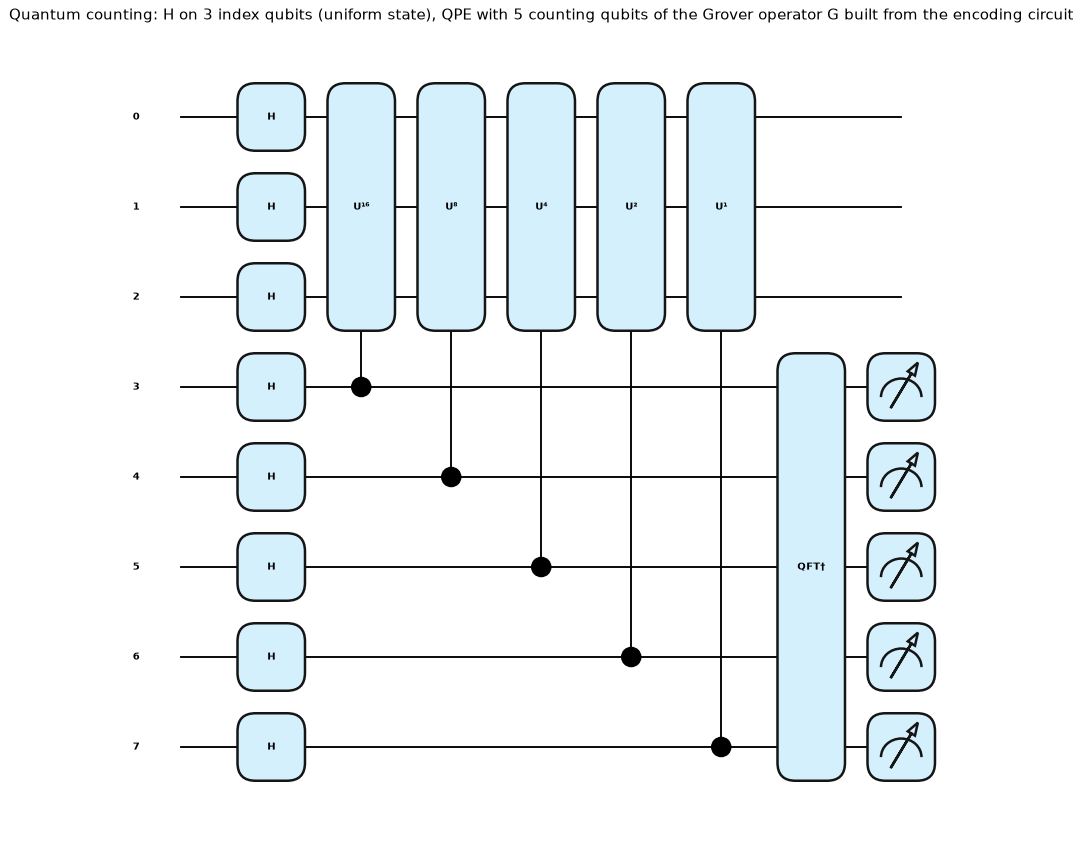

counting circuit: {'qubits': 8, 'depth': 7, 'gates': 14, 'depth_native': 7, 'gates_native': 14} | trainable parameters: 0 (G is fixed by the clients' bits)
true K = sum a*b = 3 of N = 8; max |circuit outcome distribution - analytic QPE table| = 7.98e-16
most likely outcome y = 7 -> estimate N sin^2(pi y/2^t) = 3.22


5 random 16-item instances, t = 4: max |circuit - analytic QPE table| = 1.17e-15


In [17]:
# Quantum counting circuit: G = (2|s><s| - 1) O, with O read off the executed encoding circuit, then QPE with t counting qubits
def grover_from_signs(sign):
    Nn = len(sign); return (2 * np.ones((Nn, Nn)) / Nn - np.eye(Nn)) @ np.diag(sign)
T_DEMO = 5
G_demo = grover_from_signs(np.round(sign_from_circuit))
est_w = list(range(BQ_NIDX, BQ_NIDX + T_DEMO))
dev_qpe = qml.device("default.qubit", wires=BQ_NIDX + T_DEMO)
@qml.qnode(dev_qpe)
def counting_circuit(G):
    for w_ in range(BQ_NIDX):
        qml.Hadamard(wires=w_)
    for j_, w_ in enumerate(est_w):                      # explicit QPE: H, controlled-G^(2^(t-1-j)), inverse QFT
        qml.Hadamard(wires=w_)
    for j_, w_ in enumerate(est_w):
        qml.ctrl(qml.pow(qml.QubitUnitary(G, wires=list(range(BQ_NIDX))), 2 ** (T_DEMO - 1 - j_)), control=w_)
    qml.adjoint(qml.QFT)(wires=est_w)
    return qml.probs(wires=est_w)
fig, ax = qml.draw_mpl(counting_circuit, decimals=1, style="pennylane", fontsize=8)(G_demo)
plt.title("Quantum counting: H on 3 index qubits (uniform state), QPE with 5 counting qubits of the Grover operator G built from the encoding circuit"); plt.show()
print("counting circuit:", stats(counting_circuit, G_demo), "| trainable parameters: 0 (G is fixed by the clients' bits)")
p_circ = np.asarray(counting_circuit(G_demo)); K_true = int((a_demo * b_demo).sum())
tab = qpe_table(BQ_N, T_DEMO)[K_true]
print(f"true K = sum a*b = {K_true} of N = {BQ_N}; max |circuit outcome distribution - analytic QPE table| = {np.abs(p_circ - tab).max():.2e}")
y_best = int(np.argmax(p_circ)); print("most likely outcome y =", y_best, "-> estimate N sin^2(pi y/2^t) =", round(BQ_N * np.sin(np.pi * y_best / 2 ** T_DEMO) ** 2, 3))
assert np.abs(p_circ - tab).max() < 1e-9
# a second, larger instance (4 index qubits, random bits) checked without drawing
worst = 0.0
for s in range(5):
    r_ = np.random.default_rng(100 + s); Nn = 16
    mk = (r_.integers(0, 2, Nn) * r_.integers(0, 2, Nn)); G2 = grover_from_signs(1 - 2 * mk)
    dv = qml.device("default.qubit", wires=4 + 4)
    @qml.qnode(dv)
    def c2(G):
        for w_ in range(4): qml.Hadamard(wires=w_)
        qml.QuantumPhaseEstimation(qml.QubitUnitary(G, wires=list(range(4))), estimation_wires=list(range(4, 8)))
        return qml.probs(wires=list(range(4, 8)))
    worst = max(worst, np.abs(np.asarray(c2(G2)) - qpe_table(Nn, 4)[int(mk.sum())]).max())
print(f"5 random 16-item instances, t = 4: max |circuit - analytic QPE table| = {worst:.2e}")
assert worst < 1e-9

## 3. Utility: does hiding the gradients cost accuracy?

The paper's closing claim (Sec. V) is that, unlike differential privacy, the quantum protocols "do not compromise privacy for
diminished utility". We train the same softmax model with FedSGD for `ROUNDS` rounds, with **identical mini-batches for every
protocol** (a common random stream per seed), so any difference in test accuracy comes from the aggregation step alone.
Classical references that do not use federation (centralised logistic regression, RBF-SVC, random forest, all on the same
1280 training images) are included as context; the Gaussian-noise rows are the classical privacy baseline of Appendix B.

In [18]:
RES = {}   # numbers collected for the final verdict table

def run_fl(agg, seed, rounds=None):
    rounds = ROUNDS if rounds is None else rounds
    rb = np.random.default_rng(1000 + seed)         # mini-batch stream: shared by all protocols for a given seed
    rp = np.random.default_rng(2000 + seed)         # protocol randomness (shots, masks, counting outcomes, DP noise)
    th = np.zeros(D_PARAM); accs = []
    for r in range(rounds):
        G = np.stack([local_grad(th, X_tr[ix], Y_tr1h[ix]) for ix in [rb.choice(CLIENT_IDX[k], BATCH, replace=False) for k in range(M)]])
        a, _ = agg(G, W_CLIENT, rp)
        th = th - LR * a                              # Eq. 2
        accs.append(test_acc(th))
    return np.array(accs), th

RUNS = dict(AGGREGATORS)
for s_ in DP_SIGMAS:
    RUNS[f"Gaussian noise sigma={s_}"] = make_agg_dp(s_)
ACC, TIME, THETA_T = {}, {}, {}
for nm, f in RUNS.items():
    t0 = time.time(); curves = []
    for sd in range(N_SEEDS):
        c, th = run_fl(f, sd); curves.append(c)
        if sd == 0: THETA_T[nm] = th
    ACC[nm] = np.array(curves); TIME[nm] = (time.time() - t0) / N_SEEDS
    print(f"{nm:28s} final test accuracy {100 * ACC[nm][:, -1].mean():5.2f} +- {100 * ACC[nm][:, -1].std():4.2f} %  ({TIME[nm]:5.1f} s per run)")
RES["acc"] = {k: (ACC[k][:, -1].mean(), ACC[k][:, -1].std()) for k in ACC}

plain FedAvg                 final test accuracy 93.61 +- 0.58 %  (  0.6 s per run)


classical secret sharing     final test accuracy 93.61 +- 0.58 %  (  1.1 s per run)


QFL GHZ                      final test accuracy 93.56 +- 0.54 %  ( 14.6 s per run)


QFL multiparty sum           final test accuracy 93.56 +- 0.54 %  (  0.9 s per run)


QFL BQBC                     final test accuracy 93.67 +- 0.41 %  ( 32.5 s per run)


Gaussian noise sigma=0.01    final test accuracy 94.06 +- 0.52 %  (  0.6 s per run)


Gaussian noise sigma=0.03    final test accuracy 91.67 +- 0.72 %  (  0.6 s per run)


Gaussian noise sigma=0.1     final test accuracy 75.83 +- 1.33 %  (  0.7 s per run)


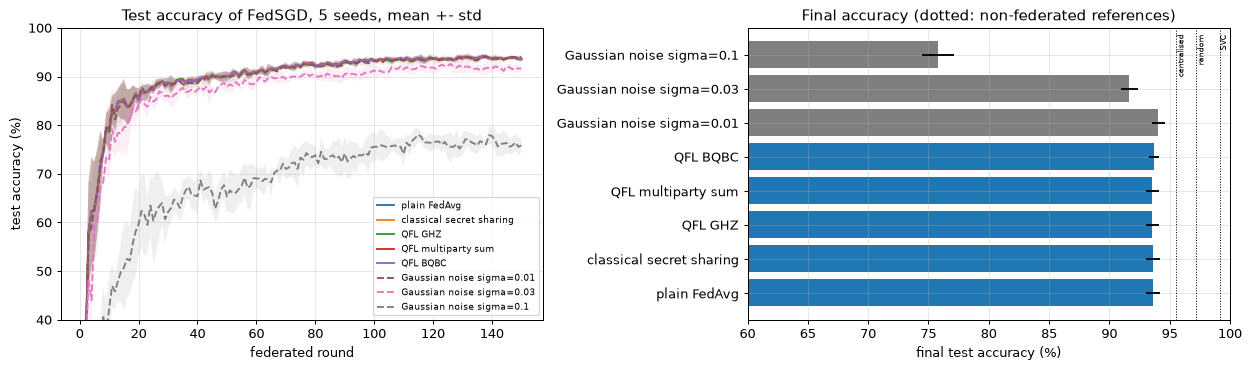

{'centralised logistic regression': 95.56, 'SVC (RBF)': 99.17, 'random forest': 97.22}


In [19]:
# classical (non-federated) references on identical inputs
refs = {}
t0 = time.time(); lr_c = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_tr, y_tr); refs["centralised logistic regression"] = lr_c.score(X_te, y_te)
svc = SVC(kernel="rbf", random_state=SEED).fit(X_tr, y_tr); refs["SVC (RBF)"] = svc.score(X_te, y_te)
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(X_tr, y_tr); refs["random forest"] = rf.score(X_te, y_te)
RES["refs"] = refs

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
x_ = np.arange(1, ROUNDS + 1)
for nm in ACC:
    m_, s_ = ACC[nm].mean(0), ACC[nm].std(0)
    ls = "--" if nm.startswith("Gaussian") else "-"
    ax[0].plot(x_, 100 * m_, ls, label=nm); ax[0].fill_between(x_, 100 * (m_ - s_), 100 * (m_ + s_), alpha=0.12)
ax[0].set_xlabel("federated round"); ax[0].set_ylabel("test accuracy (%)"); ax[0].set_ylim(40, 100)
ax[0].set_title(f"Test accuracy of FedSGD, {N_SEEDS} seeds, mean +- std"); ax[0].legend(fontsize=7, loc="lower right")
names = list(ACC); fin = [100 * ACC[n][:, -1].mean() for n in names]; err = [100 * ACC[n][:, -1].std() for n in names]
cols = ["tab:blue" if not n.startswith("Gaussian") else "tab:gray" for n in names]
ax[1].barh(names, fin, xerr=err, color=cols)
for k_, v_ in refs.items():
    ax[1].axvline(100 * v_, ls=":", color="k", lw=0.8); ax[1].text(100 * v_, len(names) - 0.4, k_.split(" ")[0], rotation=90, fontsize=6, va="top")
ax[1].set_xlim(60, 100); ax[1].set_xlabel("final test accuracy (%)"); ax[1].set_title("Final accuracy (dotted: non-federated references)")
plt.tight_layout(); plt.show()
print({k: round(100 * v, 2) for k, v in refs.items()})

### 3.1 How the precision knob of each protocol affects accuracy

Each protocol has one knob (GHZ shots, summation register size `h`, counting qubits `t`). Sweeping it shows where the "no loss
of utility" claim holds and what the knob costs. One seed, `SWEEP_ROUNDS` rounds.

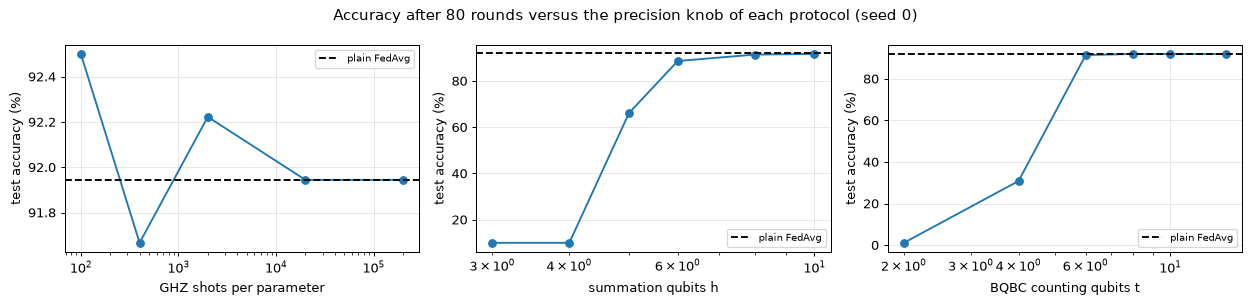

GHZ shots per parameter: 100: 92.5 %, 400: 91.7 %, 2000: 92.2 %, 20000: 91.9 %, 200000: 91.9 %
summation qubits h: 3: 10.0 %, 4: 10.0 %, 5: 66.1 %, 6: 88.6 %, 8: 91.4 %, 10: 91.7 %
BQBC counting qubits t: 2: 1.1 %, 4: 30.8 %, 6: 91.4 %, 8: 91.9 %, 10: 91.9 %, 14: 91.9 %
plain FedAvg reference after the same number of rounds: 91.9 %


In [20]:
def final_acc(agg, rounds=None, seed=0):
    rounds = SWEEP_ROUNDS if rounds is None else rounds
    return run_fl(agg, seed, rounds)[0][-1]
base_plain = final_acc(agg_plain)
sweeps = {
    "GHZ shots per parameter": ([100, 400, 2000, 20000, 200000], lambda v: (lambda G, w, rng: agg_ghz(G, w, rng, shots=v))),
    "summation qubits h": ([3, 4, 5, 6, 8, 10], lambda v: (lambda G, w, rng: agg_sms(G, w, rng, h=v))),
    "BQBC counting qubits t": ([2, 4, 6, 8, 10, 14], lambda v: (lambda G, w, rng: agg_bqbc(G, w, rng, t=v))),
}
SWEEP_RES = {}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a_, (nm, (vals, mk)) in zip(ax, sweeps.items()):
    accs_ = [final_acc(mk(v)) for v in vals]; SWEEP_RES[nm] = (vals, accs_)
    a_.semilogx(vals, 100 * np.array(accs_), "o-"); a_.axhline(100 * base_plain, ls="--", color="k", label="plain FedAvg")
    a_.set_xlabel(nm); a_.set_ylabel("test accuracy (%)"); a_.legend(fontsize=8)
plt.suptitle(f"Accuracy after {SWEEP_ROUNDS} rounds versus the precision knob of each protocol (seed 0)"); plt.tight_layout(); plt.show()
for nm, v in SWEEP_RES.items():
    print(f"{nm}: " + ", ".join(f"{a_}: {100 * float(b_):.1f} %" for a_, b_ in zip(v[0], v[1])))
print("plain FedAvg reference after the same number of rounds:", round(100 * float(base_plain), 1), "%")

## 4. What the eavesdropper recovers: gradient inversion with and without protection

The honest-but-curious server runs the Appendix-A ratio attack on **what it actually observes** in each scheme, with every
client contributing one image per round (batch size 1, the worst case):

* **plain FedAvg**: the server sees every client's gradient;
* **classical secret sharing**: the server sees the masked values `y_i` (uniform in a modulus), and only the sum is meaningful;
* **quantum GHZ, multiparty summation, BQBC**: the server obtains a (noisy) estimate of the **aggregate** `sum_k w_k grad_k`
  and nothing else. We also show the attack on the **exact** aggregate (an ideal secure-aggregation protocol), to separate the leakage
  inherent to the aggregate itself from the extra effect of protocol noise;
* **Gaussian noise**: classical differential-privacy-style baseline.

Reconstruction quality is the pixel mean squared error to the true private image (reconstruction clipped to `[0, 1]`).
For per-client schemes the number is averaged over the four clients; for aggregate schemes the attacker produces **one** image per
round, scored against the closest client image (most favourable to the attacker). The reference is the MSE of the training
mean image, i.e. an attacker who knows nothing. The attack is run at the initial model (all-zero parameters) and at the trained model.

In [21]:
def mse_clip(x, t):
    return float(np.mean((np.clip(x, 0, 1) - t) ** 2))
def corr_img(x, t):
    x = np.clip(x, 0, 1)
    return 0.0 if x.std() < 1e-12 or t.std() < 1e-12 else float(np.corrcoef(x, t)[0, 1])

ATTACKERS = {"plain FedAvg": agg_plain, "classical secret sharing": agg_css}
for s_ in DP_SIGMAS: ATTACKERS[f"Gaussian noise sigma={s_}"] = make_agg_dp(s_)
AGG_ATTACKERS = {"ideal secure aggregation (exact sum)": agg_plain, "QFL GHZ": agg_ghz, "QFL multiparty sum": agg_sms, "QFL BQBC": agg_bqbc}

def attack_eval(theta, n_trials, seed):
    rng = np.random.default_rng(seed); out = {}; gallery = None
    base = []
    for tr in range(n_trials):
        idx = [int(rng.choice(CLIENT_IDX[k])) for k in range(M)]
        G = np.stack([local_grad(theta, X_tr[i:i + 1], Y_tr1h[i:i + 1]) for i in idx]); imgs = X_tr[idx]
        base.append(np.mean([mse_clip(MEAN_IMG, im) for im in imgs]))
        rec_store = {}
        for nm, f in ATTACKERS.items():
            _, obs = f(G, W_CLIENT, rng)
            recs = [invert_image(v)[0] for v in obs["values"]]
            out.setdefault(nm, []).append((np.mean([mse_clip(r_, im) for r_, im in zip(recs, imgs)]),
                                           np.mean([corr_img(r_, im) for r_, im in zip(recs, imgs)])))
            rec_store[nm] = recs
        for nm, f in AGG_ATTACKERS.items():
            agg, obs = f(G, W_CLIENT, rng)
            rec = invert_image(agg)[0]
            ms_ = [mse_clip(rec, im) for im in imgs]; best = int(np.argmin(ms_))
            out.setdefault(nm, []).append((min(ms_), corr_img(rec, imgs[best])))
            rec_store[nm] = rec
        if tr == 0:
            gallery = (imgs, rec_store, [int(y_tr[i]) for i in idx])
    df = pd.DataFrame({k: dict(MSE=np.mean([v[0] for v in vs]), MSE_std=np.std([v[0] for v in vs]),
                               corr=np.mean([v[1] for v in vs]),
                               share_recovered=np.mean([v[0] < 0.005 for v in vs])) for k, vs in out.items()}).T
    df.loc["no information (training mean image)"] = dict(MSE=np.mean(base), MSE_std=np.std(base), corr=0.0, share_recovered=0.0)
    return df, gallery

ATT = {}
for lbl, th in [("initial model (theta = 0)", np.zeros(D_PARAM)), ("trained model (plain FedAvg, seed 0)", THETA_T["plain FedAvg"])]:
    t0 = time.time(); ATT[lbl] = attack_eval(th, ATTACK_TRIALS, 7)
    print(f"=== {lbl} | {ATTACK_TRIALS} trials, one private image per client | {time.time() - t0:.0f} s ===")
    print(ATT[lbl][0].round(4).to_string())
RES["attack"] = {k: v[0] for k, v in ATT.items()}

=== initial model (theta = 0) | 500 trials, one private image per client | 103 s ===
                                         MSE  MSE_std    corr  share_recovered
plain FedAvg                          0.0000   0.0000  1.0000            1.000
classical secret sharing              0.2822   0.0266 -0.0032            0.000
Gaussian noise sigma=0.01             0.0021   0.0004  0.9941            1.000
Gaussian noise sigma=0.03             0.0174   0.0036  0.9475            0.000
Gaussian noise sigma=0.1              0.1447   0.0354  0.4819            0.000
ideal secure aggregation (exact sum)  0.0071   0.0077  0.9757            0.600
QFL GHZ                               0.0073   0.0079  0.9750            0.596
QFL multiparty sum                    0.0078   0.0084  0.9730            0.566
QFL BQBC                              0.0071   0.0076  0.9756            0.600
no information (training mean image)  0.0730   0.0076  0.0000            0.000


=== trained model (plain FedAvg, seed 0) | 500 trials, one private image per client | 143 s ===
                                         MSE  MSE_std    corr  share_recovered
plain FedAvg                          0.0000   0.0000  1.0000            1.000
classical secret sharing              0.2824   0.0253 -0.0017            0.000
Gaussian noise sigma=0.01             0.0980   0.0493  0.6475            0.000
Gaussian noise sigma=0.03             0.1838   0.0501  0.3159            0.000
Gaussian noise sigma=0.1              0.2503   0.0347  0.0630            0.000
ideal secure aggregation (exact sum)  0.0042   0.0079  0.9854            0.768
QFL GHZ                               0.0060   0.0088  0.9798            0.666
QFL multiparty sum                    0.0043   0.0079  0.9852            0.772
QFL BQBC                              0.0042   0.0079  0.9852            0.772
no information (training mean image)  0.0732   0.0077  0.0000            0.000


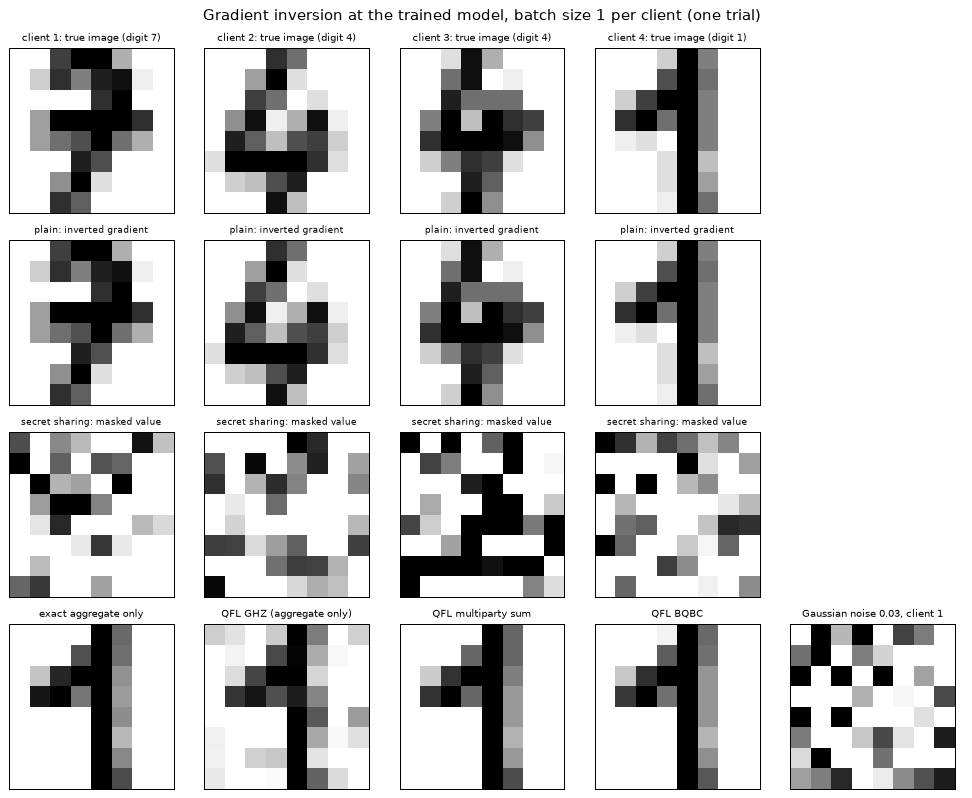

In [22]:
lbl = "trained model (plain FedAvg, seed 0)"
imgs, recs, labs = ATT[lbl][1]
fig, ax = plt.subplots(4, 5, figsize=(11, 9))
for k in range(M):
    ax[0, k].imshow(imgs[k].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[0, k].set_title(f"client {k + 1}: true image (digit {labs[k]})", fontsize=8)
    ax[1, k].imshow(np.clip(recs["plain FedAvg"][k], 0, 1).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[1, k].set_title("plain: inverted gradient", fontsize=7)
    ax[2, k].imshow(np.clip(recs["classical secret sharing"][k], 0, 1).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[2, k].set_title("secret sharing: masked value", fontsize=7)
ax[3, 0].imshow(np.clip(recs["ideal secure aggregation (exact sum)"], 0, 1).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[3, 0].set_title("exact aggregate only", fontsize=8)
ax[3, 1].imshow(np.clip(recs["QFL GHZ"], 0, 1).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[3, 1].set_title("QFL GHZ (aggregate only)", fontsize=8)
ax[3, 2].imshow(np.clip(recs["QFL multiparty sum"], 0, 1).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[3, 2].set_title("QFL multiparty sum", fontsize=8)
ax[3, 3].imshow(np.clip(recs["QFL BQBC"], 0, 1).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[3, 3].set_title("QFL BQBC", fontsize=8)
ax[3, 4].imshow(np.clip(recs["Gaussian noise sigma=0.03"][0], 0, 1).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[3, 4].set_title("Gaussian noise 0.03, client 1", fontsize=8)
for a_ in ax.ravel(): a_.set_xticks([]); a_.set_yticks([]); a_.grid(False)
ax[0, 4].axis("off"); ax[1, 4].axis("off"); ax[2, 4].axis("off")
plt.suptitle("Gradient inversion at the trained model, batch size 1 per client (one trial)"); plt.tight_layout(); plt.show()

**How to read the attack table.** Plain FedAvg is inverted exactly (MSE 0). The masked values of classical secret sharing are
uniform in the modulus, so the same attack returns noise (its clipped MSE is even worse than guessing the mean image).
The three quantum protocols hand the server the same number as an ideal secure-aggregation protocol, so their rows match the
"exact sum" row up to protocol noise: **they protect individual gradients, not the aggregate**, and with batch size 1 and
four clients the aggregate still lets the Appendix-A ratio attack recover a client image well. The Gaussian-noise rows are
the classical way to degrade that leakage, at the accuracy price shown in section 3.

| Scheme | What the server observes | Individual gradients hidden? | Accuracy cost (section 3) |
|---|---|---|---|
| plain FedAvg | every client's gradient | no | none |
| classical secret sharing | masked values, only the sum is meaningful | yes (one-time pad) | none |
| QFL GHZ | one phase = the sum, shot noise | yes if the GHZ state is honestly prepared | shot noise only |
| QFL multiparty sum | register `L` holding the sum mod 2 pi | yes if client 1 is honest and checks | grid rounding only |
| QFL BQBC | phase-encoded index state, counting result | partly (single-copy leakage, section 4.2) | counting error only |
| Gaussian noise | every client's noisy gradient | partly | grows with sigma |

### 4.1 What the quantum states themselves reveal (privacy tests on the circuits)

1. **Invariance**: the server-visible quantum state (GHZ readout probabilities; the register `L` of the summation protocol before
   the server's inverse QFT) depends on the clients' values **only through their sum**. Two different splits with the same sum must
   give identical states. A different sum must give a different state.
2. **Malicious server against GHZ** (paper Eq. 23): a server that entangles only client `j` reads `phi_j` exactly.
3. **Malicious client against the summation protocol**: a client that applies an inverse QFT to the ancilla copy and measures it
   is detected by client 1's ancilla check with the probability computed exactly below.

In [23]:
rg = np.random.default_rng(SEED)
# (1a) GHZ: different splits of the same total phase give identical readout distributions
tot = 0.40; sp_a = rg.dirichlet(np.ones(M)) * tot; sp_b = rg.dirichlet(np.ones(M)) * tot; sp_c = rg.dirichlet(np.ones(M)) * 0.55
pa = np.asarray(ghz_full_probs(np.stack([sp_a, sp_b, sp_c]), "X")); pay = np.asarray(ghz_full_probs(np.stack([sp_a, sp_b, sp_c]), "Y"))
inv_ghz = max(np.abs(pa[0] - pa[1]).max(), np.abs(pay[0] - pay[1]).max()); diff_ghz = np.abs(pa[0] - pa[2]).max()
print(f"GHZ: two different splits of the same sum  -> max difference of the full output distribution = {inv_ghz:.1e}")
print(f"GHZ: a different sum (0.55 vs 0.40)         -> max difference = {diff_ghz:.2e}")
# (1b) summation protocol: the density matrix of register L before the server's inverse QFT
h_, nc_ = 3, 3; qs = make_sms_state_qnode(h_, nc_)
rho1 = np.asarray(qs([1, 4, 3])); rho2 = np.asarray(qs([6, 0, 2])); rho3 = np.asarray(qs([1, 4, 4]))
inv_sms = np.abs(rho1 - rho2).max(); diff_sms = np.abs(rho1 - rho3).max()
print(f"summation: splits (1,4,3) and (6,0,2) both sum to 0 mod 8 -> max |rho_L difference| = {inv_sms:.1e};  sum 1 mod 8 instead: {diff_sms:.2f}")
assert inv_ghz < 1e-12 and diff_ghz > 1e-3 and inv_sms < 1e-12 and diff_sms > 0.1

# (2) malicious server against GHZ (Eq. 23): entangles only client j
phi_true = np.array([[0.31, -0.18, 0.22, 0.09]]); j_t = 3
px_h = np.asarray(ghz_server_probs(phi_true, "X"))[0, 0]; py_h = np.asarray(ghz_server_probs(phi_true, "Y"))[0, 0]
px_m = np.asarray(ghz_malicious_probs(phi_true, j_t, "X"))[0, 0]; py_m = np.asarray(ghz_malicious_probs(phi_true, j_t, "Y"))[0, 0]
est_h = np.arctan2(1 - 2 * py_h, 2 * px_h - 1); est_m = np.arctan2(1 - 2 * py_m, 2 * px_m - 1)
print(f"honest GHZ state: server learns {est_h:+.4f} = sum of phases ({phi_true.sum():+.4f}); the individual phases are {np.round(phi_true[0], 2)}")
print(f"malicious server entangling only client {j_t}: learns {est_m:+.4f} = phi_{j_t} exactly ({phi_true[0, j_t - 1]:+.4f})")
assert abs(est_m - phi_true[0, j_t - 1]) < 1e-9 and abs(est_h - phi_true.sum()) < 1e-9

# (3) malicious client against the summation protocol
pass_prob = {}
for h_, nc_ in [(3, 3), (4, 3)]:
    qa = make_sms_attack_qnode(h_, nc_, attacker=1)
    pA1, pm1 = qa([2, 3, 1]); pA2, pm2 = qa([2 ** (h_ - 1) + 1, 0, 5])
    pass_prob[h_] = float(pA1[0])
    print(f"h={h_}: honest ancilla check passes with probability 1; with a measuring client it passes with probability {pass_prob[h_]:.4f}"
          f" (= 1/2^h = {1 / 2 ** h_:.4f}); the attacker's outcome distribution is uniform and independent of the prefix (max diff {np.abs(np.asarray(pm1) - np.asarray(pm2)).max():.1e})")
RES.update(inv_ghz=inv_ghz, inv_sms=inv_sms, ghz_mal_err=abs(est_m - phi_true[0, j_t - 1]), sms_pass=pass_prob)

GHZ: two different splits of the same sum  -> max difference of the full output distribution = 2.2e-16
GHZ: a different sum (0.55 vs 0.40)         -> max difference = 3.43e-02
summation: splits (1,4,3) and (6,0,2) both sum to 0 mod 8 -> max |rho_L difference| = 1.3e-16;  sum 1 mod 8 instead: 0.25
honest GHZ state: server learns +0.4400 = sum of phases (+0.4400); the individual phases are [ 0.31 -0.18  0.22  0.09]
malicious server entangling only client 3: learns +0.2200 = phi_3 exactly (+0.2200)


h=3: honest ancilla check passes with probability 1; with a measuring client it passes with probability 0.1250 (= 1/2^h = 0.1250); the attacker's outcome distribution is uniform and independent of the prefix (max diff 1.4e-17)
h=4: honest ancilla check passes with probability 1; with a measuring client it passes with probability 0.0625 (= 1/2^h = 0.0625); the attacker's outcome distribution is uniform and independent of the prefix (max diff 1.4e-17)


### 4.2 Information that the BQBC state leaks about one client bit (an extension, not claimed by the paper)

The paper argues that a server measuring the index qubits of the BQBC state learns a given bit with probability only `1/(m l0)`.
The test above confirms that the computational-basis statistics are independent of the clients' bits. A stronger statement is
about *any* measurement on one copy of the returned state. For one client bit `b_target` (with all other gradient bits
uniformly random and unknown, weight bits `a` public) the exact state ensembles `rho_0, rho_1` are computed by enumeration; the
**Holevo information** upper-bounds the bits learnable, and the **Helstrom** probability `1/2 (1 + ||rho_0 - rho_1||_1 / 2)` is the best
single-copy guess of the bit. We also test the redundant encoding of Theorem 1 (Eq. 16) with parameter `r`.

single copy of the returned BQBC state, one client bit, other bits random:
    Holevo information (bits)  optimal guess probability
4                       0.572                      0.793
8                       0.418                      0.729
12                      0.324                      0.688
16                      0.278                      0.673

redundant encoding, 4 base items, redundancy r (state has 4 r items):
   Holevo information (bits)  optimal guess probability
1                      0.623                      0.822
2                      0.394                      0.741
4                      0.192                      0.654

classical plain FedAvg reveals the bit with probability 1.0; classical secret sharing 0.5


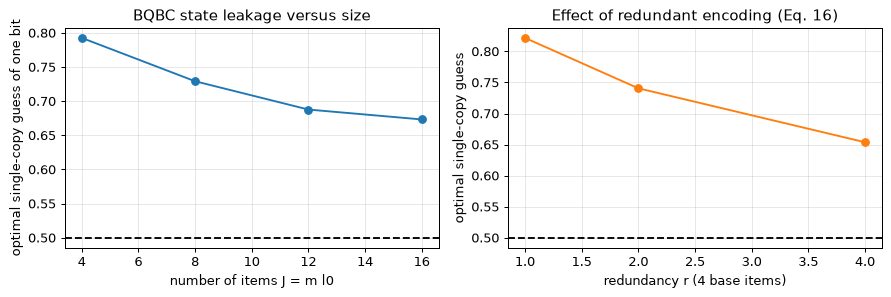

In [24]:
def vn_entropy(rho):
    ev = np.linalg.eigvalsh(rho); ev = ev[ev > 1e-12]; return float(-(ev * np.log2(ev)).sum())

def leak_one_bit(states0, states1):
    # states*: arrays (n, dim) of real pure states (equal prior) -> Holevo information and Helstrom success probability
    r0 = states0.T @ states0 / len(states0); r1 = states1.T @ states1 / len(states1)
    chi = vn_entropy((r0 + r1) / 2) - 0.5 * (vn_entropy(r0) + vn_entropy(r1))
    tn = np.abs(np.linalg.eigvalsh(r0 - r1)).sum()
    return chi, 0.5 * (1 + tn / 2)

def bqbc_states(a, b_rows):
    return (1 - 2 * a[None, :] * b_rows) / np.sqrt(len(a))

rg = np.random.default_rng(SEED); LEAK = {}
for J in (4, 8, 12, 16):
    chis, succ = [], []
    for _ in range(HOLEVO_DRAWS):
        a = rg.integers(0, 2, J); a[0] = 1                                      # target item must have a=1, otherwise nothing leaks
        B = ((np.arange(2 ** (J - 1))[:, None] >> np.arange(J - 1)) & 1)
        rows0 = np.concatenate([np.zeros((len(B), 1), int), B], 1); rows1 = np.concatenate([np.ones((len(B), 1), int), B], 1)
        c_, s_ = leak_one_bit(bqbc_states(a, rows0), bqbc_states(a, rows1)); chis.append(c_); succ.append(s_)
    LEAK[J] = (np.mean(chis), np.mean(succ))
# redundant encoding (Eq. 16): base items J0 = 4, each bit is stored in a random one of r positions, the others are 0
def leak_redundant(J0, r, a_base):
    a = np.repeat(a_base, r)                                                    # a'_{i,j} = a_i (Eq. 15)
    def strings(b_target):
        # enumerate all (random position, bit) choices of the other J0-1 items plus the random position of the target
        others = np.array(list(itertools.product(range(2 * r), repeat=J0 - 1)))
        tgt = np.arange(r)
        S = []
        for R in tgt:
            for row in others:
                s = np.zeros(J0 * r, int); s[R] = b_target
                for it, v in enumerate(row):
                    pos, bit = v % r, v // r; s[(it + 1) * r + pos] = bit
                S.append(s)
        return np.array(S)
    return leak_one_bit(bqbc_states(a, strings(0)), bqbc_states(a, strings(1)))
RED = {}
for r_ in (1, 2, 4):
    vals = []
    for _ in range(max(5, HOLEVO_DRAWS // 2)):
        ab = rg.integers(0, 2, 4); ab[0] = 1; vals.append(leak_redundant(4, r_, ab))
    RED[r_] = tuple(np.mean(vals, 0))
print("single copy of the returned BQBC state, one client bit, other bits random:")
print(pd.DataFrame(LEAK, index=["Holevo information (bits)", "optimal guess probability"]).T.round(3).to_string())
print("\nredundant encoding, 4 base items, redundancy r (state has 4 r items):")
print(pd.DataFrame(RED, index=["Holevo information (bits)", "optimal guess probability"]).T.round(3).to_string())
print("\nclassical plain FedAvg reveals the bit with probability 1.0; classical secret sharing 0.5")
RES["leak"] = LEAK; RES["leak_red"] = RED
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(list(LEAK), [v[1] for v in LEAK.values()], "o-"); ax[0].axhline(0.5, ls="--", color="k"); ax[0].set_xlabel("number of items J = m l0"); ax[0].set_ylabel("optimal single-copy guess of one bit"); ax[0].set_title("BQBC state leakage versus size")
ax[1].plot(list(RED), [v[1] for v in RED.values()], "o-", color="tab:orange"); ax[1].axhline(0.5, ls="--", color="k"); ax[1].set_xlabel("redundancy r (4 base items)"); ax[1].set_ylabel("optimal single-copy guess"); ax[1].set_title("Effect of redundant encoding (Eq. 16)")
plt.tight_layout(); plt.show()

In [25]:
# Redundant encoding is still decodable (Eqs. 15 to 18): the server recovers sum_k sum_i a_ki b_ki after the clients' one-bit messages
rg = np.random.default_rng(SEED); ok = True
for trial in range(200):
    m_, l0_, r_ = 4, 8, int(rg.integers(2, 7))
    a = rg.integers(0, 2, (m_, l0_)); b = rg.integers(0, 2, (m_, l0_)); total = 0.0
    for k in range(m_):
        use17 = rg.random() < 0.5                              # client chooses Eq. 16 (False) or Eq. 17 (True), tells the server by 1 classical bit
        bp = np.zeros((l0_, r_), int)
        for i in range(l0_):
            R_ = rg.integers(r_)
            if use17: bp[i, :] = 1; bp[i, R_] = b[k, i]
            else:     bp[i, R_] = b[k, i]
        ap = np.repeat(a[k][:, None], r_, 1)
        val = (ap * bp).sum() / (r_ * l0_)                     # what the correlator returns for this client (Eq. 18)
        if use17: val -= (r_ - 1) / (r_ * l0_) * a[k].sum()    # server removes the known offset
        total += val * r_ * l0_
    ok &= abs(total - (a * b).sum()) < 1e-9
print("redundant-encoding decoding exact in 200 random instances (m=4, l0=8, r in 2..6):", ok)
RES["redundant_ok"] = bool(ok)

redundant-encoding decoding exact in 200 random instances (m=4, l0=8, r in 2..6): True


## 5. Estimation error and communication cost versus the paper's scaling laws (Table I)

Each protocol estimates the aggregated value to some error `eps`. The paper's claims: GHZ needs `O(1/eps^2)` repetitions
(Eq. 24), BQBC and the summation protocol need `O(1/eps)` (Eqs. 14, 31). We measure the estimation error as a function of the
resource (shots, counting qubits `t`, register qubits `h`) with the exact circuit outputs, and fit log-log slopes.
Quantum counting has a heavy-tailed error (the QPE sinc tail), so we report the *median* absolute error for the slope and the
probability of a wrong integer count separately.

fitted slopes of log(error) versus log(resource): GHZ shots -0.498 (paper: -1/2 in shots, i.e. eps^-2), summation 2^h -1.004 (paper: -1), BQBC 2^t -1.000 (paper: -1)
 t  median |f_hat - f|  P(wrong integer count), worst K same, median of 5 runs
 4            0.035092                         1.000000                1.0e+00
 5            0.027408                         1.000000                1.0e+00
 6            0.011108                         1.000000                1.0e+00
 7            0.004697                         0.223895                7.8e-02
 8            0.003604                         0.185415                4.7e-02
 9            0.001020                         0.068773                2.9e-03
10            0.000768                         0.038205                5.3e-04
11            0.000432                         0.020156                7.9e-05
12            0.000138                         0.008524                6.1e-06
13            0.000099                      

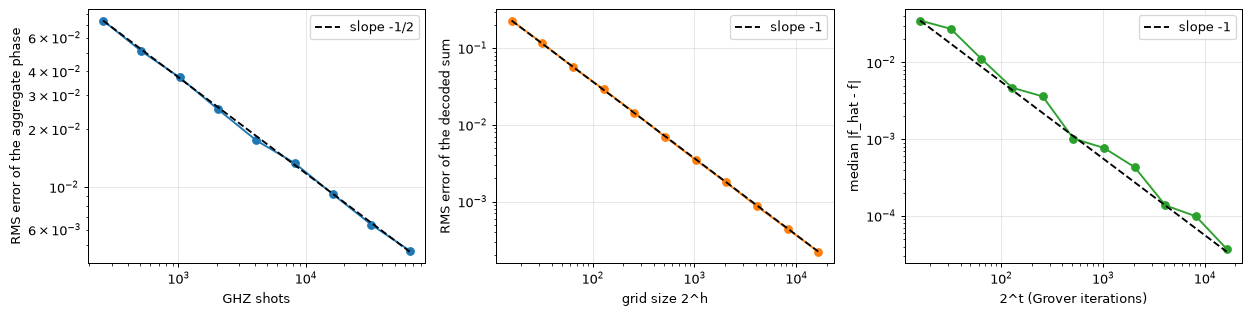

In [26]:
rg = np.random.default_rng(SEED); n_tr = SCALING_TRIALS
# (a) GHZ: error of the aggregate phase versus shots (exact circuit probabilities + binomial sampling)
shots_list = [2 ** e for e in range(8, 17)]
phi_s = rg.uniform(-1.0, 1.0, size=(n_tr, 1)) * np.array([[0.4, 0.3, 0.2, 0.1]])
pX = np.clip(np.asarray(ghz_server_probs(phi_s, "X"))[:, 0], 0, 1); pY = np.clip(np.asarray(ghz_server_probs(phi_s, "Y"))[:, 0], 0, 1)
err_ghz = []
for S in shots_list:
    n = S // 2
    est = np.arctan2(1 - 2 * rg.binomial(n, pY) / n, 2 * rg.binomial(n, pX) / n - 1)
    err_ghz.append(np.sqrt(np.mean((est - phi_s.sum(1)) ** 2)))
slope_ghz = np.polyfit(np.log(shots_list), np.log(err_ghz), 1)[0]
# (b) multiparty summation: error of the decoded sum versus h (quantisation)
h_list = list(range(4, 15)); err_sms = []
Gs = rg.uniform(-0.3, 0.3, size=(M, n_tr))
for h in h_list:
    est = sms_decode(sms_quantise(PHASE_SCALE * W_CLIENT[:, None] * Gs, h).sum(0) % 2 ** h, h)
    err_sms.append(np.sqrt(np.mean((est - PHASE_SCALE * (W_CLIENT[:, None] * Gs).sum(0)) ** 2)))
slope_sms = np.polyfit(np.log(2.0 ** np.array(h_list)), np.log(err_sms), 1)[0]
# (c) BQBC: error of the estimated marked fraction versus counting qubits (median absolute error), failure rate of the integer count
t_list = list(range(4, 15)); err_bq, fail_bq, fail_med = [], [], []
Kt = rg.integers(1, N_PAD, size=n_tr * 4)
for t in t_list:
    f_hat = count_estimate(Kt, N_PAD, t, rg) / N_PAD
    err_bq.append(np.median(np.abs(f_hat - Kt / N_PAD)))
    tab = qpe_table(N_PAD, t); yv = np.arange(2 ** t); Kest = np.rint(N_PAD * np.sin(np.pi * yv / 2 ** t) ** 2)
    pf = np.array([tab[K][Kest != K].sum() for K in range(N_PAD + 1)]).max()
    fail_bq.append(pf); fail_med.append(sum(math.comb(BQBC_REP, j) * pf ** j * (1 - pf) ** (BQBC_REP - j) for j in range(BQBC_REP // 2 + 1, BQBC_REP + 1)))
slope_bq = np.polyfit(np.log(2.0 ** np.array(t_list)), np.log(err_bq), 1)[0]
print(f"fitted slopes of log(error) versus log(resource): GHZ shots {slope_ghz:+.3f} (paper: -1/2 in shots, i.e. eps^-2),"
      f" summation 2^h {slope_sms:+.3f} (paper: -1), BQBC 2^t {slope_bq:+.3f} (paper: -1)")
print(pd.DataFrame({"t": t_list, "median |f_hat - f|": np.round(err_bq, 6), "P(wrong integer count), worst K": np.round(fail_bq, 6),
                    f"same, median of {BQBC_REP} runs": [f"{v:.1e}" for v in fail_med]}).to_string(index=False))
RES.update(slope_ghz=slope_ghz, slope_sms=slope_sms, slope_bq=slope_bq, fail_bq=dict(zip(t_list, fail_bq)))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].loglog(shots_list, err_ghz, "o-"); ax[0].loglog(shots_list, err_ghz[0] * (np.array(shots_list) / shots_list[0]) ** -0.5, "k--", label="slope -1/2"); ax[0].set_xlabel("GHZ shots"); ax[0].set_ylabel("RMS error of the aggregate phase"); ax[0].legend()
ax[1].loglog(2.0 ** np.array(h_list), err_sms, "o-", color="tab:orange"); ax[1].loglog(2.0 ** np.array(h_list), err_sms[0] * (2.0 ** np.array(h_list) / 2.0 ** h_list[0]) ** -1, "k--", label="slope -1"); ax[1].set_xlabel("grid size 2^h"); ax[1].set_ylabel("RMS error of the decoded sum"); ax[1].legend()
ax[2].loglog(2.0 ** np.array(t_list), err_bq, "o-", color="tab:green"); ax[2].loglog(2.0 ** np.array(t_list), err_bq[0] * (2.0 ** np.array(t_list) / 2.0 ** t_list[0]) ** -1, "k--", label="slope -1"); ax[2].set_xlabel("2^t (Grover iterations)"); ax[2].set_ylabel("median |f_hat - f|"); ax[2].legend()
plt.tight_layout(); plt.show()

                                    kind       amount
classical secret sharing  classical bits       332800
QFL GHZ                      qubits sent    104000000
QFL multiparty sum           qubits sent        32500
QFL BQBC                     qubits sent  23960137500
fitted exponent of the cost in m (bookkeeping of the formulas, m = 2..128): {'secret sharing': np.float64(2.0), 'GHZ': np.float64(1.0), 'summation': np.float64(0.91), 'BQBC': np.float64(1.1)}


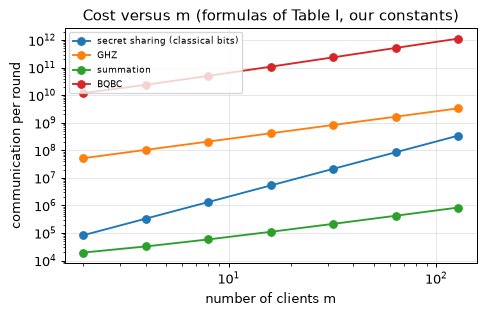

In [27]:
# Communication tally of OUR implementation for one round of the whole model (d = 650 parameters), and the scaling in m of the formulas
def comm_css(m, d):     return dict(kind="classical bits", amount=(m * (m - 1) + m) * d * CSS_R_BITS)
def comm_ghz(m, d, shots):          return dict(kind="qubits sent", amount=2 * m * d * shots)
def comm_sms(m, d, h):              return dict(kind="qubits sent", amount=(m + 1) * d * h)
def comm_bqbc(m, d, l0, t, rep):
    n = int(math.ceil(math.log2(m * l0))); return dict(kind="qubits sent", amount=rep * d * (2 * l0 - 1) * (2 ** t - 1) * (m + 1) * (n + 1))
tally = {"classical secret sharing": comm_css(M, D_PARAM), "QFL GHZ": comm_ghz(M, D_PARAM, GHZ_SHOTS),
         "QFL multiparty sum": comm_sms(M, D_PARAM, SMS_H), "QFL BQBC": comm_bqbc(M, D_PARAM, L0, BQBC_T, BQBC_REP)}
print(pd.DataFrame(tally).T.to_string())
ms_ = np.array([2, 4, 8, 16, 32, 64, 128])
c_css = np.array([comm_css(m, D_PARAM)["amount"] for m in ms_], float)
c_sms = np.array([comm_sms(m, D_PARAM, SMS_H)["amount"] for m in ms_], float)
c_ghz = np.array([comm_ghz(m, D_PARAM, GHZ_SHOTS)["amount"] for m in ms_], float)
c_bq = np.array([comm_bqbc(m, D_PARAM, L0, BQBC_T, BQBC_REP)["amount"] for m in ms_], float)
sl = {n_: np.polyfit(np.log(ms_), np.log(c), 1)[0] for n_, c in [("secret sharing", c_css), ("GHZ", c_ghz), ("summation", c_sms), ("BQBC", c_bq)]}
print("fitted exponent of the cost in m (bookkeeping of the formulas, m = 2..128):", {k: round(v, 2) for k, v in sl.items()})
RES["m_slopes"] = sl
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for lbl_, c in [("secret sharing (classical bits)", c_css), ("GHZ", c_ghz), ("summation", c_sms), ("BQBC", c_bq)]:
    ax.loglog(ms_, c, "o-", label=lbl_)
ax.set_xlabel("number of clients m"); ax.set_ylabel("communication per round"); ax.legend(fontsize=7); ax.set_title("Cost versus m (formulas of Table I, our constants)")
plt.tight_layout(); plt.show()

## 6. Paper versus this notebook: verdict per claim

The paper reports no numbers, so there is nothing to compare numerically. Each analytic or qualitative claim is turned into a
measurement above. Verdicts: **reproduced** when the claim holds within the stated tolerance, **not reached** when it fails,
**cannot be checked** when the claim depends on an attack model or a resource that the paper does not specify or that a CPU
simulation cannot test.

In [28]:
acc = RES["acc"]; base = acc["plain FedAvg"][0]
def acc_gap(nm): return 100 * (acc[nm][0] - base)
att_t = RES["attack"]["trained model (plain FedAvg, seed 0)"]; att_0 = RES["attack"]["initial model (theta = 0)"]
mean_img_mse = att_t.loc["no information (training mean image)", "MSE"]
rows = [
    ("1. Classical secret sharing aggregates exactly (Eq. 4)", "masks cancel; server gets sum w_i grad_i",
     f"max error {CSS_ERR:.1e} (fixed-point step 6e-8); masked values uniform", "reproduced" if CSS_ERR < 1e-6 else "not reached"),
    ("2a. Inversion is exact for batch size 1 (Eq. A5)", "x_i = (dL/dw_ij)/(dL/db_j)", f"max reconstruction error {max(errs1):.1e} over 200 random pairs", "reproduced"),
    ("2b. For B > 1 unknowns exceed equations, no unique solution", "n|C|+|C| equations vs B(n+|C|) unknowns",
     f"ratio attack MSE to the closest batch image: B=2 {INV_B[2]:.4f}, B=8 {INV_B[8]:.4f}, B=32 {INV_B[32]:.4f} (exact at B=1; no-information reference {float(np.mean((X_tr - MEAN_IMG) ** 2)):.4f}); the identity fails but a partial image still leaks",
     "reproduced (identity fails; partial leakage remains)"),
    ("3. GHZ readout probability (Eq. 22)", "P(0) = (1 + cos sum)/2", f"circuit vs closed form <1e-9 (also vs Qiskit); needs a second quadrature for the sign", "reproduced"),
    ("4. GHZ cost scales as eps^-2", "QC = O(m d / eps^2)", f"fitted slope {RES['slope_ghz']:+.2f} of log error vs log shots (expected -0.5)",
     "reproduced" if abs(RES["slope_ghz"] + 0.5) < 0.15 else "not reached"),
    ("5. Summation protocol returns sum mod 2 pi (Eq. 30)", "inverse QFT gives the exact sum on the grid", "full and reduced circuits give |sum mod 2^h> exactly; quantisation error ~ 2^-h (slope %+.2f)" % RES["slope_sms"],
     "reproduced" if abs(RES["slope_sms"] + 1) < 0.15 else "not reached"),
    ("6. Ancilla check detects a measuring client (Eq. 29)", "ancilla cannot be reset to |0>",
     f"detection probability {1 - RES['sms_pass'][3]:.3f} (h=3), {1 - RES['sms_pass'][4]:.3f} (h=4) for an inverse-QFT-and-measure attacker; honest runs pass with probability 1", "reproduced (detection prob. 1 - 2^-h only)"),
    ("7. Server sees only the sum (GHZ, summation)", "individual gradients hidden", f"state is invariant under re-splitting the sum (max diff {max(RES['inv_ghz'], RES['inv_sms']):.0e}); differs for another sum", "reproduced"),
    ("8. Malicious server can isolate one client in GHZ (Eq. 23)", "reads phi_j of a single client", f"error of the recovered phase {RES['ghz_mal_err']:.1e}", "reproduced"),
    ("9. BQBC estimates the correlator with O(1/eps) rounds", "quantum counting", f"slope {RES['slope_bq']:+.2f} of median error vs 2^t; but one run has a heavy tail: P(wrong integer count) = {RES['fail_bq'][BQBC_T]:.1e} at t={BQBC_T}",
     "reproduced (with a failure-probability caveat)" if abs(RES["slope_bq"] + 1) < 0.15 else "not reached"),
    ("10. Server samples a given BQBC index with prob. 1/(m l0)", "phase hidden in index qubits", "computational-basis statistics independent of the clients' bits, each index has probability 1/N", "reproduced"),
    ("11. Redundant encoding keeps the aggregate recoverable (Eqs. 15 to 18)", "server removes known offset", f"exact in 200 random instances: {RES['redundant_ok']}", "reproduced"),
    ("12. Redundant encoding lowers the server's success probability (Theorem 1)", "P decreases polynomially in r", "depends on the attack model, which the paper delegates to Ref. [7]. Extension: optimal single-copy guess of one bit for r = 1, 2, 4 is %s" % ", ".join(f"{RES['leak_red'][r][1]:.3f}" for r in (1, 2, 4)), ("direction reproduced (guess probability falls with r); the polynomial law cannot be checked (attack model not specified)" if RES["leak_red"][4][1] < RES["leak_red"][1][1] else "direction not reached; the law cannot be checked (attack model not specified)")),
    ("13. Quantum protocols cost no accuracy", "no privacy/utility trade-off",
     "gap to plain FedAvg (percentage points): " + ", ".join(f"{k.replace('QFL ', '')} {acc_gap(k):+.2f}" for k in ("classical secret sharing", "QFL GHZ", "QFL multiparty sum", "QFL BQBC")),
     "reproduced" if all(abs(acc_gap(k)) <= 1.0 for k in ("classical secret sharing", "QFL GHZ", "QFL multiparty sum", "QFL BQBC")) else "not reached"),
    ("14. Classical DP trades accuracy for privacy (Appendix B)", "reduced model accuracy", "gap (points) for sigma = " + ", ".join(f"{s}: {acc_gap(f'Gaussian noise sigma={s}'):+.2f}" for s in DP_SIGMAS), "reproduced" if acc_gap(f"Gaussian noise sigma={DP_SIGMAS[-1]}") < -1 else "not reached at these noise levels"),
    ("15. Hiding protects clients against gradient inversion (headline)", "server cannot extract individual gradients",
     f"trained model, MSE of reconstruction: plain {att_t.loc['plain FedAvg','MSE']:.4f}, secret sharing {att_t.loc['classical secret sharing','MSE']:.3f}, "
     f"QFL aggregate {att_t.loc['QFL GHZ','MSE']:.4f}/{att_t.loc['QFL multiparty sum','MSE']:.4f}/{att_t.loc['QFL BQBC','MSE']:.4f}, exact-aggregate {att_t.loc['ideal secure aggregation (exact sum)','MSE']:.4f}, no information {mean_img_mse:.4f}",
     "reproduced for individual gradients; the aggregate itself still leaks (see section 4)"),
    ("16. Communication of Table I (quadratic gain in m over secret sharing)", "O(m^2 d) vs O(m d ...)", "fitted exponents in m: " + ", ".join(f"{k} {v:.2f}" for k, v in RES["m_slopes"].items()) + " (bookkeeping of the formulas, not a measurement)", "reproduced (arithmetic only)"),
    ("17. Security against external eavesdroppers via decoy states (Sec. V)", "detect with prob. 1 - (3/4)^n_d", "not simulated (no channel model in the paper)", "cannot be checked"),
    ("18. SWAP-test variant of Sec. III A, GHZ with a trusted preparer, hardware cost", "O(log m / eps^2)", "SWAP test loses the sign of the overlap; trust assumptions are not testable on a simulator", "cannot be checked"),
]
VERDICT = pd.DataFrame(rows, columns=["Claim", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 140, "display.width", 250)
print(VERDICT[["Claim", "Verdict"]].to_string(index=False))
print()
for r_ in rows: print("-", r_[0], "\n    notebook:", r_[2])
RES["verdicts"] = VERDICT["Verdict"].tolist()
print("\nTotal notebook run time: %.1f minutes" % ((time.time() - T_NB0) / 60))

                                                                          Claim                                                                                                                  Verdict
                         1. Classical secret sharing aggregates exactly (Eq. 4)                                                                                                               reproduced
                               2a. Inversion is exact for batch size 1 (Eq. A5)                                                                                                               reproduced
                    2b. For B > 1 unknowns exceed equations, no unique solution                                                                     reproduced (identity fails; partial leakage remains)
                                            3. GHZ readout probability (Eq. 22)                                                                                                               reprod

## 7. Reading the paper critically

* **There is no experiment.** The paper proves nothing numerically; every number in this notebook comes from a workload we chose
  (digits, four clients, softmax regression). The relative statements (no accuracy loss, invariance to re-splitting, exact
  cancellation) are robust to that choice; the absolute accuracies are not the paper's.
* **The aggregate itself leaks.** All protocols hide *individual* gradients but give the server the exact (or nearly exact) weighted
  sum, because that is the functionality. With batch size 1 per client the ratio attack on the sum still reconstructs a blend of the
  clients' images, and at a trained model, where the softmax is confident, it recovers the dominant client's image almost perfectly
  (see the "exact sum" row). Quantum hiding therefore gives the same protection as ideal secure aggregation, no more.
  Larger batches, many clients and noise are what limit this leakage.
* **Single-quadrature readout.** Eq. 22 is even in the aggregate phase; the sign (and a good estimate of small phases, where the
  cosine is flat) needs a second measurement basis. We added it as a documented choice.
* **Gradient bits are not a bitwise inner product.** Eq. 8 to 9 turn a product of multi-bit numbers into `2 l0 - 1` correlators;
  Eq. 14 hides that factor (we pay it in the cost table), and quantum counting must return *exact integers* for the high-order
  correlators. One QPE run has a heavy-tailed error (a wrong integer count with probability about 2e-3 at `t = 14`, see the table in section 5), so a repetition or a
  larger `t` is needed (we used a median of 5). The paper's `O(1/eps)` is the right scaling for the typical error, not for a
  worst-case guarantee.
* **Privacy of BQBC is not "1/(m l0)".** The probability that a computational-basis measurement hits an index is `1/(m l0)`
  and tells nothing, but the exact single-copy information about one client bit is far from zero in our enumeration
  (section 4.2) because unmarked items (`a = 0`) provide a phase reference. Redundant encoding lowers it. The paper's claim is
  about a specific attack in Ref. [7]; an information-theoretic statement would need the full attack model.
* **Trust assumptions.** The GHZ protocol is broken by a malicious server unless a trusted client prepares the state; the
  summation protocol needs one trusted client that prepares the ancilla and checks it, and its detection probability against a
  measuring client is `1 - 2^-h`, not 1. Malicious clients and collusion are left open by the authors.
* **Communication.** Qubits are counted, not hardware costs: GHZ distribution over `m` parties, `10^5` shots per parameter and a
  2^14-fold Grover iteration per bit-correlator are far outside present quantum networks; the secret-sharing baseline is
  `O(m^2 d)` *classical* bits and runs today.

## 8. Exercises

1. Change `M_CLIENTS` to 2 (and adapt `CLIENT_SIZES` to two dyadic weights). What does the exact-sum attack recover now, and why is
   hiding useless for `m = 1`?
2. Raise `BATCH` to 128 and repeat section 4. How quickly does the ratio attack on the aggregate degrade? Compare with the Gaussian-noise rows.
3. Remove the second GHZ quadrature (use only `P(0) = (1 + cos)/2`) and train. What happens to the accuracy and why?
4. Set `BQBC_REP = 1` and `BQBC_T = 10`. Count how often a training round contains a wrong high-order correlator and how the accuracy reacts.
5. In section 4.2, change the prior on the other bits from uniform to "all zero". Does the single-copy leakage about the target bit grow or vanish? Explain with the state `sum (-1)^{a b}|j>`.